# Comparing Classical and Transformer-Based Models for Detecting Fake Online Reviews

**Author:** Loganathan Kajamugan  
**Institution:** South Eastern University of Sri Lanka  
**Supervisor:** Prof HMM Naleer

## About this notebook

This is a cleaned **Colab experiment record**, not a verified one-click pipeline. It documents experiments conducted across multiple sessions. Code, selected historical result tables, and explanations are provided for inspection. Model weights and review datasets are not embedded.

**Do not use Run all on your only copy of the saved artifacts.** Upload prompts require the specified files; some cells write results to Drive. Make a separate working directory for a rerun. Existing dated checkpoint paths identify the original runs and must be updated to your own artifacts. Mounting your Drive does not give access to the author's files.

### Research questions
1. How do TF-IDF Logistic Regression, Linear SVM, a combined TF-IDF/style SVM, and DistilBERT compare?
2. Do eight writing-style features improve classification?
3. How do the saved source-trained models transfer between datasets?

### Data and experimental scope
- Product: 40,404 cleaned reviews; original (0) versus computer-generated (1). Train/validation/test: 28,282 / 6,064 / 6,058. Related-review groups remain within one split.
- Hotel: 1,596 cleaned reviews; truthful (0) versus deceptive (1). Original folds 1–3 train, fold 4 validation, fold 5 test: 956 / 320 / 320. Hotels are disjoint across splits.
- Across datasets, no normalized exact matches or three-word-set Jaccard matches at or above 0.90 were found among eligible texts. This does not exclude paraphrases.
- Transfer changes both domain and label meaning; it does not isolate domain shift, establish annotation scarcity as its cause, or implement domain adaptation.

### Environment and required inputs
Experiments used Google Colab and a Tesla T4 for DistilBERT. Recorded versions: transformers 5.20.2, datasets 4.8.5, accelerate 1.15.0. Other dependencies include torch, scikit-learn, pandas, numpy, scipy, matplotlib, joblib, tqdm, datasketch, and threadpoolctl. Exact versions for other libraries should be taken from the saved experiment metadata; this notebook does not claim to pin the entire historical environment.

Obtain the original product CSV (`category`, `rating`, `label`, `text_`) from the dataset source used in the study and the hotel archive `op_spam_v1.4.zip` from its authors. Respect their licences. Dataset source documentation should accompany the repository; no third-party review data is bundled here.

Upload prompts distinguish the raw product CSV from saved `train.csv` and `validation.csv`. Drive paths use `/content/drive/MyDrive/Fake_Review_Research`. Later evaluation sections require saved classical pipelines, combined bundles, six DistilBERT checkpoints with tokenizers, and the original splits. Re-running training creates new dated paths that must replace the historical paths in evaluation cells.

### Execution and provenance
Selected outputs below are retained from the submitted notebook; they were **not regenerated during cleanup**. Outputs containing raw reviews, upload widgets, download logs, errors and progress bars were removed. All execution counters were reset. The final 24 prediction-consistency checks passed in the original run; a clean-session end-to-end rerun has not been verified.

The first seed-123 product model was lost after a runtime reset. Final comparisons use its saved recovery run. The hotel training cell was run separately with seeds 42, 123 and 2026; the submitted code retains the last setting, 2026. Change only the seed and run it separately for each seed when reproducing. Do not select seeds by target/test performance.

## Final test results
Macro-F1 (%); DistilBERT is the mean of three individually evaluated seeds, not an ensemble.

| Model | Product → product | Hotel → hotel | Product → hotel | Hotel → product |
|---|---:|---:|---:|---:|
| Logistic Regression | 93.64 | 89.37 | 35.38 | 35.93 |
| TF-IDF SVM | 94.21 | 89.69 | 34.71 | 35.98 |
| TF-IDF + style SVM | 94.57 | 88.43 | 33.33 | 41.48 |
| DistilBERT | 97.82 | 87.26 | 34.28 | 60.62 |

Product-test paired duplicate-group bootstrap intervals (exploratory, 2,000 draws) were +2.65 to +3.81 percentage points for product-trained DistilBERT mean minus combined SVM, −0.08 to +0.79 for combined minus TF-IDF SVM, and +17.71 to +20.69 for hotel-trained DistilBERT mean minus combined SVM. These condition on saved models and do not capture retraining uncertainty. Four test hotels limit hotel-level generalization. Inference benchmarks compare CPU classical models with GPU DistilBERT, not identical hardware.


## 1. Product data: exploratory analysis

Upload the original product CSV. These descriptive checks preceded splitting and are preliminary exploration, not evidence of general deception cues. Whitespace word counts here differ from the later regex style-feature counts.

In [ ]:
from google.colab import files
import pandas as pd
import io

# Select the original CSV file from your laptop
uploaded = files.upload()

# Read the uploaded file
filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

# Report size without displaying raw review text
print("Original dataset rows:", len(df))

In [ ]:
# Count words by splitting each review at spaces and other whitespace
# The original review text remains unchanged
df["word_count"] = df["text_"].fillna("").str.split().str.len()

# Calculate review counts, average length and median length
summary = df.groupby("label")["word_count"].agg(
    reviews="count",
    average_words="mean",
    median_words="median"
)

# Replace the short labels with understandable names
summary = summary.rename(index={
    "OR": "Original",
    "CG": "Computer-generated"
})

# Display the results
summary.round(2)

,reviews,average_words,median_words
label,,,
Computer-generated,20216,61.29,35.0
Original,20216,73.64,42.0


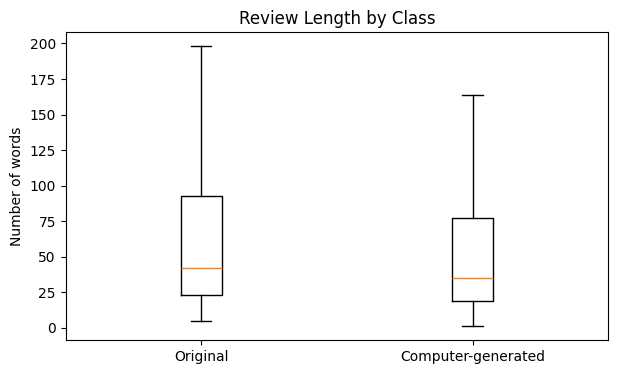

In [ ]:
import matplotlib.pyplot as plt

# Collect word counts for each class
original = df.loc[df["label"] == "OR", "word_count"]
generated = df.loc[df["label"] == "CG", "word_count"]

# Compare the middle values and spread of review lengths
plt.figure(figsize=(7, 4))

plt.boxplot(
    [original, generated],
    labels=["Original", "Computer-generated"],
    showfliers=False
)

plt.ylabel("Number of words")
plt.title("Review Length by Class")
plt.show()

In [ ]:
# Check for "never buy", ignoring capitalisation
# This creates a new column without changing the original text
df["has_never_buy"] = df["text_"].str.contains(
    "never buy", case=False, regex=False, na=False
)

# Count matching reviews and calculate their percentage in each class
phrase_summary = df.groupby("label")["has_never_buy"].agg(
    matching_reviews="sum",
    total_reviews="count"
)

phrase_summary["percentage"] = (
    phrase_summary["matching_reviews"]
    / phrase_summary["total_reviews"] * 100
)

phrase_summary.rename(index={
    "OR": "Original",
    "CG": "Computer-generated"
}).round(2)

,matching_reviews,total_reviews,percentage
label,,,
Computer-generated,4,20216,0.02
Original,16,20216,0.08


## 2. Product cleaning and duplicate grouping

Preserve original review text. Remove exact/normalized duplicates, inspect approximate near-duplicate candidates, and group related texts before splitting. MinHash candidate generation is approximate.

In [ ]:
# Find all rows whose review text occurs more than once
# keep=False includes both the first occurrence and its duplicates
duplicates = df[df.duplicated(subset="text_", keep=False)]

# Display matching reviews together
duplicates = duplicates.sort_values("text_")

print("Rows involved in duplicate-text groups:", len(duplicates))

display(
    duplicates[["category", "rating", "label", "text_"]].head(10)
)

In [ ]:
# Check whether identical review texts have conflicting labels
label_counts = df.groupby("text_")["label"].nunique()
conflicts = label_counts[label_counts > 1]

print("Review texts with conflicting labels:", len(conflicts))

# Stop if conflicting labels need investigation
assert len(conflicts) == 0, "Investigate conflicting labels first."

# Keep one copy of each exact review text
# The original dataframe remains unchanged
df_unique = df.drop_duplicates(subset="text_", keep="first").copy()

print("Original rows:", len(df))
print("Rows removed:", len(df) - len(df_unique))
print("Remaining rows:", len(df_unique))

# Check the remaining class counts
print("\nReviews per label:")
print(df_unique["label"].value_counts())

In [ ]:
# Create a comparison key without changing the original review text
df_unique["text_key"] = (
    df_unique["text_"]
    .str.casefold()                         # Ignore capitalisation
    .str.replace(r"\s+", " ", regex=True)   # Standardise whitespace
    .str.strip()                           # Remove surrounding spaces
)

# Count additional duplicates after this normalisation
extra_duplicates = df_unique.duplicated(
    subset="text_key", keep="first"
).sum()

# Check whether matching texts have different labels
label_counts = df_unique.groupby("text_key")["label"].nunique()
conflicting_groups = (label_counts > 1).sum()

print("Additional duplicate rows:", extra_duplicates)
print("Groups with conflicting labels:", conflicting_groups)

In [ ]:
# Keep one review for each normalised text
# Original spelling, punctuation and capitalisation stay in text_
df_clean = df_unique.drop_duplicates(
    subset="text_key", keep="first"
).copy()

# Preserve the original CSV row number for tracking
df_clean["review_id"] = df_clean.index

# Reset the dataframe's row numbering
df_clean = df_clean.reset_index(drop=True)

print("Remaining reviews:", len(df_clean))
print("\nReviews per label:")
print(df_clean["label"].value_counts())

# Confirm that no normalised duplicates remain
assert df_clean["text_key"].is_unique

In [ ]:
!pip -q install datasketch

In [ ]:
import re
from datasketch import MinHash, MinHashLSH
from tqdm.auto import tqdm

# Represent a review as a set of consecutive three-word phrases
def get_phrases(text):
    words = re.findall(r"\b\w+\b", text.casefold())

    return {
        " ".join(words[i:i + 3])
        for i in range(len(words) - 2)
    }

# Use a broader search threshold to find possible matches
lsh = MinHashLSH(threshold=0.8, num_perm=128)

texts = df_clean["text_"].tolist()
near_duplicate_pairs = []
short_reviews = 0

for i, text in enumerate(tqdm(texts, desc="Checking reviews")):
    phrases = get_phrases(text)

    # Reviews with fewer than three words need a separate check
    if not phrases:
        short_reviews += 1
        continue

    # Create a compact signature for this review
    signature = MinHash(num_perm=128, seed=42)
    signature.update_batch([
        phrase.encode("utf-8") for phrase in sorted(phrases)
    ])

    # Compare only with likely matches already in the index
    for j in sorted(lsh.query(signature)):
        other_phrases = get_phrases(texts[j])

        # Exact Jaccard similarity of the phrase sets
        similarity = (
            len(phrases & other_phrases)
            / len(phrases | other_phrases)
        )

        # Flag pairs sharing at least 90% of their combined phrase set
        if similarity >= 0.90:
            near_duplicate_pairs.append((j, i, similarity))

    lsh.insert(i, signature)

print("Highly similar pairs found:", len(near_duplicate_pairs))
print("Short reviews excluded from this check:", short_reviews)

In [ ]:
# Show the five pairs with the highest similarity
top_pairs = sorted(
    near_duplicate_pairs,
    key=lambda pair: pair[2],
    reverse=True
)[:5]

for number, (i, j, similarity) in enumerate(top_pairs, start=1):
    print(f"\nPAIR {number} | Similarity: {similarity:.3f}")

    print(f"\nReview A | Label: {df_clean.iloc[i]['label']}")
    print(df_clean.iloc[i]["text_"])

    print(f"\nReview B | Label: {df_clean.iloc[j]['label']}")
    print(df_clean.iloc[j]["text_"])

    print("-" * 70)

# Count flagged pairs whose labels disagree
conflicting_pairs = sum(
    df_clean.iloc[i]["label"] != df_clean.iloc[j]["label"]
    for i, j, similarity in near_duplicate_pairs
)

print("\nFlagged pairs with different labels:", conflicting_pairs)

In [ ]:
# Start with every review in its own group
parent = list(range(len(df_clean)))

# Find the representative of a review's group
def find_group(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i

# Join the groups of each flagged pair
for i, j, similarity in near_duplicate_pairs:
    root_i = find_group(i)
    root_j = find_group(j)
    parent[root_j] = root_i

# Assign a group ID to every review
df_clean["duplicate_group"] = [
    find_group(i) for i in range(len(df_clean))
]

# Summarise groups containing multiple reviews
group_sizes = df_clean["duplicate_group"].value_counts()
shared_groups = group_sizes[group_sizes > 1]

print("Groups containing related reviews:", len(shared_groups))
print("Reviews in these groups:", shared_groups.sum())
print("Largest group:", group_sizes.max())

# Inspect the two reviews excluded from the three-word phrase check
short_mask = df_clean["text_"].apply(
    lambda text: len(get_phrases(text)) == 0
)

print("\nShort reviews:")
display(df_clean.loc[short_mask, ["review_id", "label", "text_"]])

In [ ]:
# Keep reviews containing at least one letter or number
has_content = df_clean["text_"].apply(
    lambda text: any(character.isalnum() for character in text)
)

# Show all reviews excluded by this rule
print("Reviews with no letters or numbers:")
display(df_clean.loc[~has_content, ["review_id", "label", "text_"]])

# Create the dataset we will split
# Preserve review_id and duplicate_group
df_ready = df_clean.loc[has_content].copy()
df_ready = df_ready.reset_index(drop=True)

print("\nRemaining reviews:", len(df_ready))
print("\nReviews per label:")
print(df_ready["label"].value_counts())

assert df_ready["review_id"].is_unique
assert df_ready["duplicate_group"].notna().all()

## 3. Product split and classical baselines

Use the group-aware saved split; fit vocabulary and models on training data and select hyperparameters using validation only.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# First split: approximately 70% training and 30% remaining
first_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, remaining_idx = next(
    first_split.split(
        df_ready,
        groups=df_ready["duplicate_group"]
    )
)

train_df = df_ready.iloc[train_idx].copy()
remaining_df = df_ready.iloc[remaining_idx].copy()

# Second split: divide the remaining groups equally
# This gives approximately 15% validation and 15% testing
second_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    second_split.split(
        remaining_df,
        groups=remaining_df["duplicate_group"]
    )
)

val_df = remaining_df.iloc[val_idx].copy()
test_df = remaining_df.iloc[test_idx].copy()

# Confirm that no related-review group crosses between splits
train_groups = set(train_df["duplicate_group"])
val_groups = set(val_df["duplicate_group"])
test_groups = set(test_df["duplicate_group"])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# Confirm that every review appears exactly once
all_ids = pd.concat([
    train_df["review_id"],
    val_df["review_id"],
    test_df["review_id"]
])

assert len(all_ids) == len(df_ready)
assert all_ids.is_unique

# Display split sizes and class balance
summary_rows = []

for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    summary_rows.append({
        "split": name,
        "reviews": len(data),
        "percentage": 100 * len(data) / len(df_ready),
        "OR": (data["label"] == "OR").sum(),
        "CG": (data["label"] == "CG").sum()
    })

split_summary = pd.DataFrame(summary_rows).set_index("split")

display(split_summary.round(2))
print("Checks passed: no shared groups or repeated review IDs.")

,reviews,percentage,OR,CG
split,,,,
Training,28282,70.00,14174,14108
Validation,6064,15.01,3022,3042
Testing,6058,14.99,3019,3039


In [ ]:
from pathlib import Path
import shutil
from google.colab import files

# Create a folder for the saved datasets
output_folder = Path("/content/product_review_splits")
output_folder.mkdir(exist_ok=True)

# Save only the source columns and tracking information
# Exploratory features will be calculated separately
columns = [
    "review_id",
    "category",
    "rating",
    "label",
    "text_",
    "duplicate_group"
]

train_df[columns].to_csv(output_folder / "train.csv", index=False)
val_df[columns].to_csv(output_folder / "validation.csv", index=False)
test_df[columns].to_csv(output_folder / "test.csv", index=False)

# Save a record of which split each review belongs to
assignments = pd.concat([
    train_df[["review_id", "duplicate_group"]].assign(split="train"),
    val_df[["review_id", "duplicate_group"]].assign(split="validation"),
    test_df[["review_id", "duplicate_group"]].assign(split="test")
], ignore_index=True)

assignments.to_csv(output_folder / "split_assignments.csv", index=False)

# Save the counts for your research records
split_summary.to_csv(output_folder / "split_summary.csv")

# Download everything as one ZIP file
zip_path = shutil.make_archive(
    "/content/product_review_splits",
    "zip",
    output_folder
)

files.download(zip_path)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
import time

# Convert labels into numbers
# 0 = original; 1 = computer-generated
label_mapping = {"OR": 0, "CG": 1}

y_train = train_df["label"].map(label_mapping)
y_val = val_df["label"].map(label_mapping)

# The pipeline converts text into TF-IDF features,
# then passes those features to Logistic Regression
lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 1)  # Start with individual words
    )),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=1000,
        random_state=42
    ))
])

# Fit both TF-IDF and the classifier using training data only
start_time = time.perf_counter()

lr_pipeline.fit(train_df["text_"], y_train)

training_seconds = time.perf_counter() - start_time

# Predict labels for validation reviews
val_predictions = lr_pipeline.predict(val_df["text_"])

# Display validation results
print(f"Training time: {training_seconds:.2f} seconds")
print(f"Validation accuracy: {accuracy_score(y_val, val_predictions):.4f}")
print(f"Validation macro-F1: {f1_score(y_val, val_predictions, average='macro'):.4f}")

print("\nValidation classification report:")
print(classification_report(
    y_val,
    val_predictions,
    labels=[0, 1],
    target_names=["Original", "Computer-generated"],
    digits=4,
    zero_division=0
))

In [ ]:
from sklearn.svm import LinearSVC

# Use the same TF-IDF settings as Logistic Regression
svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 1)
    )),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

# Train using training reviews only
start_time = time.perf_counter()

svm_pipeline.fit(train_df["text_"], y_train)

svm_training_seconds = time.perf_counter() - start_time

# Predict validation labels
svm_val_predictions = svm_pipeline.predict(val_df["text_"])

# Display results
print(f"Training time: {svm_training_seconds:.2f} seconds")
print(
    f"Validation accuracy: "
    f"{accuracy_score(y_val, svm_val_predictions):.4f}"
)
print(
    f"Validation macro-F1: "
    f"{f1_score(y_val, svm_val_predictions, average='macro'):.4f}"
)

print("\nValidation classification report:")
print(classification_report(
    y_val,
    svm_val_predictions,
    labels=[0, 1],
    target_names=["Original", "Computer-generated"],
    digits=4,
    zero_division=0
))

In [ ]:
from sklearn.base import clone

# Keep the original baseline models unchanged
models = {
    "Logistic Regression": lr_pipeline,
    "Linear SVM": svm_pipeline
}

tuning_results = []
best_models = {}
best_scores = {}

for model_name, baseline in models.items():
    best_scores[model_name] = -1

    for ngrams in [(1, 1), (1, 2)]:
        for c_value in [0.1, 1.0, 10.0]:

            # Create a fresh model with the chosen settings
            model = clone(baseline)

            model.set_params(
                tfidf__ngram_range=ngrams,
                classifier__C=c_value
            )

            # Fit TF-IDF and the classifier on training data only
            start = time.perf_counter()
            model.fit(train_df["text_"], y_train)
            elapsed = time.perf_counter() - start

            # Evaluate on validation data
            predictions = model.predict(val_df["text_"])

            accuracy = accuracy_score(y_val, predictions)
            macro_f1 = f1_score(
                y_val, predictions, average="macro"
            )

            tuning_results.append({
                "model": model_name,
                "ngrams": str(ngrams),
                "C": c_value,
                "accuracy": accuracy,
                "macro_f1": macro_f1,
                "training_seconds": elapsed
            })

            # Retain the best model for each classifier family
            if macro_f1 > best_scores[model_name]:
                best_scores[model_name] = macro_f1
                best_models[model_name] = model

            print(
                f"{model_name} | ngrams={ngrams} | "
                f"C={c_value} | macro-F1={macro_f1:.4f}"
            )

# Show all settings, ordered by validation macro-F1
tuning_table = pd.DataFrame(tuning_results).sort_values(
    "macro_f1", ascending=False
)

display(tuning_table.round(4))

,model,ngrams,C,accuracy,macro_f1,training_seconds
11,Linear SVM,"(1, 2)",10.0,0.9436,0.9436,8.5515
10,Linear SVM,"(1, 2)",1.0,0.9413,0.9413,5.9524
5,Logistic Regression,"(1, 2)",10.0,0.9365,0.9365,11.3408
9,Linear SVM,"(1, 2)",0.1,0.9235,0.9235,5.5576
4,Logistic Regression,"(1, 2)",1.0,0.9184,0.9184,7.7064
2,Logistic Regression,"(1, 1)",10.0,0.9045,0.9045,3.0077
7,Linear SVM,"(1, 1)",1.0,0.9037,0.9037,2.4862
6,Linear SVM,"(1, 1)",0.1,0.9017,0.9017,2.2032
1,Logistic Regression,"(1, 1)",1.0,0.9011,0.9011,3.5856
8,Linear SVM,"(1, 1)",10.0,0.8870,0.8870,3.3150


In [ ]:
import joblib
import json
import sklearn
import shutil
from pathlib import Path
from google.colab import files

save_folder = Path("/content/classical_baselines")
save_folder.mkdir(exist_ok=True)

# Save each complete pipeline: TF-IDF + trained classifier
joblib.dump(
    best_models["Linear SVM"],
    save_folder / "svm_pipeline.joblib",
    compress=3
)

joblib.dump(
    best_models["Logistic Regression"],
    save_folder / "lr_pipeline.joblib",
    compress=3
)

# Save all 12 tuning results
tuning_table.to_csv(
    save_folder / "validation_tuning_results.csv",
    index=False
)

# Save validation predictions for later comparisons
predictions = val_df[["review_id", "label"]].copy()

predictions["svm_prediction"] = best_models["Linear SVM"].predict(
    val_df["text_"]
)

predictions["lr_prediction"] = best_models[
    "Logistic Regression"
].predict(val_df["text_"])

predictions.to_csv(
    save_folder / "validation_predictions.csv",
    index=False
)

# Record label meanings and software version
metadata = {
    "label_mapping": {"OR": 0, "CG": 1},
    "selection_metric": "validation macro-F1",
    "selected_classifier": "Linear SVM",
    "sklearn_version": sklearn.__version__,
    "test_set_evaluated": False
}

with open(save_folder / "metadata.json", "w") as file:
    json.dump(metadata, file, indent=2)

# Download the saved models and results together
zip_path = shutil.make_archive(
    "/content/classical_baselines",
    "zip",
    save_folder
)

files.download(zip_path)

## 4. Product style and combined models

Upload the saved product training and validation files. The eight style features and manual lexicon are fixed operational definitions, not verified signs of deception. The obsolete non-convergent dual=True combined-model fit was removed; preparation and the converged dual=False fit remain.

In [ ]:
import pandas as pd
import io
from google.colab import files

uploaded = files.upload()  # Select train.csv only
filename = next(iter(uploaded))

train_df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Training reviews:", len(train_df))

In [ ]:
import re
import pandas as pd
import numpy as np

# Fixed word list for our experiment
# These words alone do not prove that a review is fake
EXAGGERATION_WORDS = {
    "amazing", "awesome", "fantastic", "incredible",
    "perfect", "excellent", "outstanding", "best",
    "worst", "terrible", "awful", "horrible"
}

def extract_style_features(text):
    # Find alphabetic words, including words with apostrophes
    words = re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?", text)
    lower_words = [word.lower() for word in words]

    word_count = len(words)
    safe_count = max(word_count, 1)

    # Approximate sentence boundaries using punctuation
    sentences = [
        part for part in re.split(r"[.!?]+", text)
        if re.search(r"[A-Za-z]", part)
    ]

    letters = [character for character in text if character.isalpha()]

    return {
        "word_count": word_count,

        "avg_word_length":
            sum(len(word) for word in words) / safe_count,

        "avg_sentence_length":
            word_count / max(len(sentences), 1),

        "exclamation_per_100_words":
            text.count("!") / safe_count * 100,

        "question_per_100_words":
            text.count("?") / safe_count * 100,

        "uppercase_proportion":
            sum(letter.isupper() for letter in letters)
            / max(len(letters), 1),

        "repeated_word_proportion":
            (word_count - len(set(lower_words))) / safe_count,

        "exaggeration_per_100_words":
            sum(word in EXAGGERATION_WORDS for word in lower_words)
            / safe_count * 100
    }

# Calculate features without changing the original review text
train_style = pd.DataFrame(
    [extract_style_features(text) for text in train_df["text_"]],
    index=train_df.index
)

# Check for invalid values
assert np.isfinite(train_style.to_numpy()).all()

print("Feature table shape:", train_style.shape)
display(train_style.head().round(3))

,word_count,avg_word_length,avg_sentence_length,exclamation_per_100_words,question_per_100_words,uppercase_proportion,repeated_word_proportion,exaggeration_per_100_words
0,13,4.385,3.25,15.385,0.0,0.070,0.154,0.0
1,14,3.714,7.00,0.000,0.0,0.038,0.143,0.0
2,17,3.647,8.50,5.882,0.0,0.032,0.059,0.0
3,8,4.500,8.00,0.000,0.0,1.000,0.000,0.0
4,17,3.647,17.00,0.000,0.0,0.033,0.118,0.0


In [ ]:
import io
from google.colab import files

# Upload validation.csv from your saved splits
uploaded = files.upload()
filename = next(iter(uploaded))

val_df = pd.read_csv(io.BytesIO(uploaded[filename]))

# Apply exactly the same feature-extraction function
val_style = pd.DataFrame(
    [extract_style_features(text) for text in val_df["text_"]],
    index=val_df.index
)

# Prepare numerical labels
label_mapping = {"OR": 0, "CG": 1}

y_train = train_df["label"].map(label_mapping)
y_val = val_df["label"].map(label_mapping)

# Check feature consistency and valid values
assert train_style.columns.equals(val_style.columns)
assert np.isfinite(val_style.to_numpy()).all()
assert y_train.notna().all() and y_val.notna().all()

# Confirm that training and validation remain separate
assert set(train_df["review_id"]).isdisjoint(val_df["review_id"])
assert set(train_df["duplicate_group"]).isdisjoint(
    val_df["duplicate_group"]
)

print("Validation feature shape:", val_style.shape)
print("Checks passed.")


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
import time

style_results = []
best_style_model = None
best_style_score = -1

for c_value in [0.1, 1.0, 10.0]:

    # Scale the eight features, then train Linear SVM
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LinearSVC(
            C=c_value,
            dual=False,
            max_iter=10000,
            random_state=42
        ))
    ])

    start = time.perf_counter()

    # Fit scaling and classification using training data only
    model.fit(train_style, y_train)

    training_seconds = time.perf_counter() - start

    # Evaluate on validation data
    predictions = model.predict(val_style)

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(y_val, predictions, average="macro")

    style_results.append({
        "C": c_value,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "training_seconds": training_seconds
    })

    # Keep the best model according to validation macro-F1
    if macro_f1 > best_style_score:
        best_style_score = macro_f1
        best_style_model = model

style_results_table = pd.DataFrame(style_results).sort_values(
    "macro_f1", ascending=False
)

display(style_results_table.round(4))

,C,accuracy,macro_f1,training_seconds
0,0.1,0.7831,0.7831,0.0528
1,1.0,0.7828,0.7828,0.0523
2,10.0,0.7828,0.7828,0.0514


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import csr_matrix, hstack

# Learn word features from training reviews only
combined_tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2)
)

train_text_features = combined_tfidf.fit_transform(train_df["text_"])
val_text_features = combined_tfidf.transform(val_df["text_"])

# Learn style-feature scaling from training data only
combined_scaler = StandardScaler()

train_style_scaled = combined_scaler.fit_transform(train_style)
val_style_scaled = combined_scaler.transform(val_style)

# Join the two feature sets without converting TF-IDF to a dense matrix
X_train_combined = hstack([
    train_text_features,
    csr_matrix(train_style_scaled)
], format="csr")

X_val_combined = hstack([
    val_text_features,
    csr_matrix(val_style_scaled)
], format="csr")


In [ ]:
import warnings
from sklearn.exceptions import ConvergenceWarning

combined_results = []
best_combined_model = None
best_combined_score = -1

for c_value in [0.1, 1.0, 10.0]:
    model = LinearSVC(
        C=c_value,
        dual=False,       # Change the optimisation method
        max_iter=20000,
        random_state=42
    )

    # Record whether this model produces a convergence warning
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)

        start = time.perf_counter()
        model.fit(X_train_combined, y_train)
        fit_seconds = time.perf_counter() - start

    converged = not any(
        issubclass(w.category, ConvergenceWarning)
        for w in caught
    )

    predictions = model.predict(X_val_combined)
    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(y_val, predictions, average="macro")

    combined_results.append({
        "C": c_value,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "classifier_fit_seconds": fit_seconds,
        "iterations": model.n_iter_,
        "converged": converged
    })

    # Select only models that finished without convergence warnings
    if converged and macro_f1 > best_combined_score:
        best_combined_score = macro_f1
        best_combined_model = model

    print(f"C={c_value} finished | Converged: {converged}")

combined_results_table = pd.DataFrame(
    combined_results
).sort_values("macro_f1", ascending=False)

display(combined_results_table.round(4))

,C,accuracy,macro_f1,classifier_fit_seconds,iterations,converged
1,1.0,0.9500,0.9500,4.3980,18,True
2,10.0,0.9500,0.9500,7.9935,30,True
0,0.1,0.9293,0.9293,7.4976,15,True


In [ ]:
from sklearn.metrics import classification_report

# Show scores with more precision
display(
    combined_results_table[
        ["C", "accuracy", "macro_f1", "converged"]
    ].round(6)
)

print(
    "Selected C:",
    best_combined_model.get_params()["C"]
)

# Predict using the selected converged model
combined_val_predictions = best_combined_model.predict(
    X_val_combined
)

print("\nValidation classification report:")
print(classification_report(
    y_val,
    combined_val_predictions,
    labels=[0, 1],
    target_names=["Original", "Computer-generated"],
    digits=4,
    zero_division=0
))

,C,accuracy,macro_f1,converged
1,1.0,0.950033,0.950033,True
2,10.0,0.950033,0.950032,True
0,0.1,0.929255,0.929253,True


In [ ]:
import joblib
import json
import shutil
import sklearn
from pathlib import Path
from google.colab import files

save_folder = Path("/content/combined_svm")
save_folder.mkdir(exist_ok=True)

# Save everything needed to transform features and classify reviews
model_bundle = {
    "tfidf": combined_tfidf,
    "style_scaler": combined_scaler,
    "classifier": best_combined_model,
    "style_feature_names": train_style.columns.tolist(),
    "exaggeration_words": sorted(EXAGGERATION_WORDS),
    "label_mapping": {"OR": 0, "CG": 1}
}

joblib.dump(
    model_bundle,
    save_folder / "combined_svm_bundle.joblib",
    compress=3
)

# Save the converged tuning results
combined_results_table.to_csv(
    save_folder / "validation_tuning_results.csv",
    index=False
)

# Preserve predictions for later model comparisons
prediction_table = val_df[["review_id", "label"]].copy()
prediction_table["prediction"] = combined_val_predictions

prediction_table.to_csv(
    save_folder / "validation_predictions.csv",
    index=False
)

# Record important settings
metadata = {
    "selected_C": best_combined_model.C,
    "tfidf_ngram_range": list(combined_tfidf.ngram_range),
    "style_feature_weight": 1.0,
    "selection_metric": "validation macro-F1",
    "sklearn_version": sklearn.__version__,
    "test_set_evaluated": False,
    "feature_extraction": "extract_style_features in the Colab notebook"
}

with open(save_folder / "metadata.json", "w") as file:
    json.dump(metadata, file, indent=2)

zip_path = shutil.make_archive(
    "/content/combined_svm", "zip", save_folder
)

files.download(zip_path)

## 5. Product feature ablation

Remove feature groups at fixed C=1. Treat the no-length variant as exploratory rather than a retrospectively selected main model.

In [ ]:
feature_groups = {
    "Length": [
        "word_count",
        "avg_word_length",
        "avg_sentence_length"
    ],
    "Punctuation and capitals": [
        "exclamation_per_100_words",
        "question_per_100_words",
        "uppercase_proportion"
    ],
    "Repetition": ["repeated_word_proportion"],
    "Exaggeration": ["exaggeration_per_100_words"]
}

# Reference score from the full combined model
full_predictions = best_combined_model.predict(X_val_combined)
full_f1 = f1_score(y_val, full_predictions, average="macro")

ablation_results = [{
    "configuration": "All style features",
    "macro_f1": full_f1,
    "change_from_full": 0.0,
    "converged": True
}]

# Include TF-IDF alone at the SAME C for a controlled comparison
experiments = {"No style features": train_style.columns.tolist()}
experiments.update(feature_groups)

for group_name, removed_features in experiments.items():

    # Find the columns that remain
    keep_indices = [
        i for i, name in enumerate(train_style.columns)
        if name not in removed_features
    ]

    # Reuse training-fitted TF-IDF and scaled style features
    X_train = hstack([
        train_text_features,
        csr_matrix(train_style_scaled[:, keep_indices])
    ], format="csr")

    X_val = hstack([
        val_text_features,
        csr_matrix(val_style_scaled[:, keep_indices])
    ], format="csr")

    model = LinearSVC(
        C=1.0,
        dual=False,
        max_iter=20000,
        random_state=42
    )

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_train, y_train)

    converged = not any(
        issubclass(w.category, ConvergenceWarning)
        for w in caught
    )

    predictions = model.predict(X_val)
    score = f1_score(y_val, predictions, average="macro")

    configuration = (
        "TF-IDF only"
        if group_name == "No style features"
        else f"Without {group_name.lower()}"
    )

    ablation_results.append({
        "configuration": configuration,
        "macro_f1": score,
        "change_from_full": score - full_f1,
        "converged": converged
    })

ablation_table = pd.DataFrame(ablation_results)
display(ablation_table.round(6))

,configuration,macro_f1,change_from_full,converged
0,All style features,0.950033,0.000000,True
1,TF-IDF only,0.941293,-0.008740,True
2,Without length,0.951186,0.001153,True
3,Without punctuation and capitals,0.948714,-0.001319,True
4,Without repetition,0.949208,-0.000824,True
5,Without exaggeration,0.950033,0.000000,True


In [ ]:
from google.colab import files

ablation_table.to_csv(
    "/content/style_feature_ablation.csv",
    index=False
)

files.download("/content/style_feature_ablation.csv")

## 6. Product DistilBERT: seed 42

Upload both product splits, tokenize at 256, and fine-tune from the base model. GPU required. Save/download the model before a runtime reset.

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("No GPU connected. Check the runtime settings.")

In [ ]:
import pandas as pd
import io
from google.colab import files

# Select both train.csv and validation.csv
uploaded = files.upload()

required_files = {"train.csv", "validation.csv"}

if not required_files.issubset(uploaded):
    raise ValueError("Please upload both train.csv and validation.csv.")

# Read the saved splits
train_df = pd.read_csv(io.BytesIO(uploaded["train.csv"]))
val_df = pd.read_csv(io.BytesIO(uploaded["validation.csv"]))

# Use the same label mapping as the classical models
label_mapping = {"OR": 0, "CG": 1}

train_df["labels"] = train_df["label"].map(label_mapping)
val_df["labels"] = val_df["label"].map(label_mapping)

# Check text and labels
for data in [train_df, val_df]:
    assert data["labels"].notna().all()
    assert data["text_"].notna().all()
    assert data["text_"].str.strip().ne("").all()

# Check that the saved split sizes match
assert len(train_df) == 28282
assert len(val_df) == 6064

# Confirm that reviews and related-review groups do not overlap
assert set(train_df["review_id"]).isdisjoint(val_df["review_id"])
assert set(train_df["duplicate_group"]).isdisjoint(
    val_df["duplicate_group"]
)

print("Training reviews:", len(train_df))
print("Validation reviews:", len(val_df))
print("Checks passed.")

In [ ]:
%pip -q install transformers datasets accelerate

In [ ]:
import transformers
import datasets
import accelerate
from transformers import AutoTokenizer
from tqdm.auto import tqdm

# Record versions for reproducibility
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)

MODEL_NAME = "distilbert/distilbert-base-uncased"
MAX_LENGTH = 256

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def get_token_lengths(texts):
    lengths = []

    # Process reviews in batches without shortening them
    for start in tqdm(range(0, len(texts), 256)):
        batch = texts[start:start + 256]

        encoded = tokenizer(
            batch,
            truncation=False,
            padding=False,
            add_special_tokens=True,
            return_length=True
        )

        lengths.extend(encoded["length"])

    return pd.Series(lengths)

# Measure lengths before applying truncation
train_token_lengths = get_token_lengths(
    train_df["text_"].tolist()
)

val_token_lengths = get_token_lengths(
    val_df["text_"].tolist()
)

for name, lengths in [
    ("Training", train_token_lengths),
    ("Validation", val_token_lengths)
]:
    above_limit = (lengths > MAX_LENGTH).sum()

    print(f"\n{name}:")
    print(f"Reviews exceeding 256 tokens: {above_limit}")
    print(f"Percentage: {100 * above_limit / len(lengths):.2f}%")

In [ ]:
from datasets import Dataset
from transformers import DataCollatorWithPadding

# Include only review text and numerical labels
train_dataset = Dataset.from_pandas(
    train_df[["text_", "labels"]],
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_df[["text_", "labels"]],
    preserve_index=False
)

# Convert text into model inputs and shorten long reviews
def tokenize_reviews(batch):
    return tokenizer(
        batch["text_"],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False
    )

train_tokenized = train_dataset.map(
    tokenize_reviews,
    batched=True,
    remove_columns=["text_"]
)

val_tokenized = val_dataset.map(
    tokenize_reviews,
    batched=True,
    remove_columns=["text_"]
)

# During training, pad reviews to the longest length in each batch
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Confirm that every sequence fits within our chosen limit
assert max(map(len, train_tokenized["input_ids"])) <= MAX_LENGTH
assert max(map(len, val_tokenized["input_ids"])) <= MAX_LENGTH

print("Training reviews:", len(train_tokenized))
print("Validation reviews:", len(val_tokenized))
print("Model input columns:", train_tokenized.column_names)
print("Tokenization checks passed.")

In [ ]:
import numpy as np
import torch
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    set_seed
)

# Remove an input that DistilBERT does not use
if "token_type_ids" in train_tokenized.column_names:
    train_tokenized = train_tokenized.remove_columns("token_type_ids")

if "token_type_ids" in val_tokenized.column_names:
    val_tokenized = val_tokenized.remove_columns("token_type_ids")

# Set the seed before creating the classification model
set_seed(42)

assert torch.cuda.is_available(), "Reconnect a GPU before training."

# Load pretrained DistilBERT with a two-class classification head
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "Original", 1: "Computer-generated"},
    label2id={"Original": 0, "Computer-generated": 1}
)

# Calculate validation metrics after each epoch
def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels, predictions, average="macro"
        )
    }

training_args = TrainingArguments(
    output_dir="/content/distilbert_checkpoints",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,

    # Evaluate and save after each epoch
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,

    # Restore the best validation checkpoint when training finishes
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    fp16=True,             # Mixed precision for the T4 GPU
    seed=42,
    data_seed=42,
    logging_steps=100,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

# Start training
training_result = trainer.train()

print("\nTraining finished.")
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation macro-F1:", trainer.state.best_metric)

In [ ]:
from pathlib import Path
import json
import shutil
import transformers
from google.colab import files

save_folder = Path("/content/distilbert_best")
save_folder.mkdir(exist_ok=True)

# trainer currently holds the best validation checkpoint
trainer.save_model(str(save_folder))
tokenizer.save_pretrained(str(save_folder))

# Save the training and validation history
pd.DataFrame(trainer.state.log_history).to_csv(
    save_folder / "training_history.csv",
    index=False
)

# Record settings needed to reproduce the experiment
metadata = {
    "base_model": MODEL_NAME,
    "max_length": MAX_LENGTH,
    "label_mapping": {"OR": 0, "CG": 1},
    "seed": 42,
    "learning_rate": 2e-5,
    "epochs_run": 3,
    "best_checkpoint": trainer.state.best_model_checkpoint,
    "best_validation_macro_f1": trainer.state.best_metric,
    "train_reviews": len(train_df),
    "validation_reviews": len(val_df),
    "transformers_version": transformers.__version__,
    "torch_version": torch.__version__,
    "test_set_evaluated": False
}

with open(save_folder / "experiment_metadata.json", "w") as file:
    json.dump(metadata, file, indent=2)

zip_path = shutil.make_archive(
    "/content/distilbert_best",
    "zip",
    save_folder
)

files.download(zip_path)

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from google.colab import files

# Predict using the best checkpoint already restored by the trainer
prediction_output = trainer.predict(val_tokenized)

distilbert_predictions = np.argmax(
    prediction_output.predictions,
    axis=1
)

true_labels = prediction_output.label_ids

# Show performance separately for each class
print("DistilBERT validation classification report:")
print(classification_report(
    true_labels,
    distilbert_predictions,
    labels=[0, 1],
    target_names=["Original", "Computer-generated"],
    digits=4,
    zero_division=0
))

# Rows = actual labels; columns = predicted labels
matrix = confusion_matrix(
    true_labels,
    distilbert_predictions,
    labels=[0, 1]
)

display(pd.DataFrame(
    matrix,
    index=["Actual Original", "Actual Generated"],
    columns=["Predicted Original", "Predicted Generated"]
))

# Save predictions with review IDs for later comparisons
prediction_table = val_df[["review_id", "label"]].copy()
prediction_table["true_label"] = true_labels
prediction_table["prediction"] = distilbert_predictions

output_path = "/content/distilbert_validation_predictions.csv"
prediction_table.to_csv(output_path, index=False)

files.download(output_path)

## 7. Product DistilBERT: retained seeds 123 and 2026

The lost initial seed-123 attempt and its failed save diagnostics were removed. This section retains the recovery run used in final results and the seed-2026 run. Drive setup/upload cells are intentional session boundaries.

In [ ]:
from google.colab import drive
from pathlib import Path
import torch

# Connect your Google Drive and follow the authorisation prompt
drive.mount("/content/drive")

# Create a persistent folder for the experiment
project_folder = Path(
    "/content/drive/MyDrive/Fake_Review_Research/DistilBERT"
)
project_folder.mkdir(parents=True, exist_ok=True)

print("Save folder:", project_folder)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

In [ ]:
from pathlib import Path
from google.colab import files
import pandas as pd
import io
import torch

project_folder = Path(
    "/content/drive/MyDrive/Fake_Review_Research/DistilBERT"
)
data_folder = project_folder / "data"
data_folder.mkdir(parents=True, exist_ok=True)

# Upload the same saved splits used in earlier experiments
uploaded = files.upload()

required = {"train.csv", "validation.csv"}
assert required.issubset(uploaded), "Upload both required CSV files."

train_df = pd.read_csv(io.BytesIO(uploaded["train.csv"]))
val_df = pd.read_csv(io.BytesIO(uploaded["validation.csv"]))

# Verify the saved splits
assert len(train_df) == 28282
assert len(val_df) == 6064
assert set(train_df["review_id"]).isdisjoint(val_df["review_id"])
assert set(train_df["duplicate_group"]).isdisjoint(
    val_df["duplicate_group"]
)

# Preserve the uploaded files exactly as they are
for filename in required:
    (data_folder / filename).write_bytes(uploaded[filename])

# Prepare the numerical labels in memory
for data in [train_df, val_df]:
    data["labels"] = data["label"].map({"OR": 0, "CG": 1})
    assert data["labels"].notna().all()
    assert data["text_"].notna().all()

print("Training reviews:", len(train_df))
print("Validation reviews:", len(val_df))
print("Data saved to Google Drive.")
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

In [ ]:
%pip -q install transformers==5.20.2 datasets==4.8.5 accelerate==1.15.0

In [ ]:
from pathlib import Path
import pandas as pd
from datasets import Dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

project_folder = Path(
    "/content/drive/MyDrive/Fake_Review_Research/DistilBERT"
)

# Load the same splits directly from Drive
train_df = pd.read_csv(project_folder / "data/train.csv")
val_df = pd.read_csv(project_folder / "data/validation.csv")

for data in [train_df, val_df]:
    data["labels"] = data["label"].map({"OR": 0, "CG": 1})
    assert data["labels"].notna().all()
    assert data["text_"].notna().all()

MODEL_NAME = "distilbert/distilbert-base-uncased"
MAX_LENGTH = 256

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_reviews(batch):
    return tokenizer(
        batch["text_"],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False,
        return_token_type_ids=False
    )

train_dataset = Dataset.from_pandas(
    train_df[["text_", "labels"]],
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_df[["text_", "labels"]],
    preserve_index=False
)

train_tokenized = train_dataset.map(
    tokenize_reviews,
    batched=True,
    remove_columns=["text_"]
)

val_tokenized = val_dataset.map(
    tokenize_reviews,
    batched=True,
    remove_columns=["text_"]
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

assert len(train_tokenized) == 28282
assert len(val_tokenized) == 6064
assert max(map(len, train_tokenized["input_ids"])) <= MAX_LENGTH
assert max(map(len, val_tokenized["input_ids"])) <= MAX_LENGTH

print("Training reviews:", len(train_tokenized))
print("Validation reviews:", len(val_tokenized))
print("Input columns:", train_tokenized.column_names)
print("Ready for seed-123 training.")

In [ ]:
import json
import numpy as np
import torch
import transformers
from datetime import datetime, timezone
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    set_seed
)

assert torch.cuda.is_available(), "Connect the T4 GPU first."
assert (project_folder / "data/train.csv").exists(), "Check Drive connection."

SEED = 123
set_seed(SEED)

# Create a separate folder to avoid overwriting another run
run_id = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
run_folder = project_folder / f"seed123_recovery_{run_id}"
run_folder.mkdir(parents=True, exist_ok=True)

# Start from the original pretrained model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "Original", 1: "Computer-generated"},
    label2id={"Original": 0, "Computer-generated": 1}
)

def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels, predictions, average="macro"
        )
    }

training_args = TrainingArguments(
    output_dir=str(run_folder / "checkpoints"),
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    fp16=True,
    seed=SEED,
    data_seed=SEED,
    logging_steps=100,
    report_to="none"
)

trainer_seed123 = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

# Train and automatically restore the best validation checkpoint
trainer_seed123.train()

# Save the selected model before running further analysis
best_folder = run_folder / "best_model"
trainer_seed123.save_model(str(best_folder))
tokenizer.save_pretrained(str(best_folder))

# Save training history
pd.DataFrame(trainer_seed123.state.log_history).to_csv(
    run_folder / "training_history.csv",
    index=False
)

# Save validation predictions
output = trainer_seed123.predict(val_tokenized)

prediction_table = val_df[["review_id", "label"]].copy()
prediction_table["prediction"] = np.argmax(output.predictions, axis=-1)
prediction_table.to_csv(
    run_folder / "validation_predictions.csv",
    index=False
)

# Save experiment details
metadata = {
    "seed": SEED,
    "base_model": MODEL_NAME,
    "max_length": MAX_LENGTH,
    "label_mapping": {"OR": 0, "CG": 1},
    "learning_rate": 2e-5,
    "epochs_run": 3,
    "best_checkpoint": trainer_seed123.state.best_model_checkpoint,
    "best_validation_macro_f1": trainer_seed123.state.best_metric,
    "transformers_version": transformers.__version__,
    "torch_version": torch.__version__,
    "test_set_evaluated": False,
    "purpose": "Recovery of lost seed-123 model"
}

with open(run_folder / "experiment_metadata.json", "w") as file:
    json.dump(metadata, file, indent=2)

print("\nTraining and saving completed.")
print("Best validation macro-F1:", trainer_seed123.state.best_metric)
print("Saved in Google Drive:", run_folder)

In [ ]:
from dataclasses import replace

SEED = 2026
set_seed(SEED)

run_id = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
third_folder = project_folder / f"seed2026_{run_id}"
third_folder.mkdir(parents=True, exist_ok=True)

# Start again from the original pretrained model
model_seed2026 = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "Original", 1: "Computer-generated"},
    label2id={"Original": 0, "Computer-generated": 1}
)

# Keep the same training settings
args_seed2026 = replace(
    training_args,
    output_dir=str(third_folder / "checkpoints"),
    seed=SEED,
    data_seed=SEED
)

trainer_seed2026 = Trainer(
    model=model_seed2026,
    args=args_seed2026,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

trainer_seed2026.train()

# Save the best validation checkpoint
best_folder = third_folder / "best_model"
trainer_seed2026.save_model(str(best_folder))
tokenizer.save_pretrained(str(best_folder))

# Save history and predictions
pd.DataFrame(trainer_seed2026.state.log_history).to_csv(
    third_folder / "training_history.csv",
    index=False
)

output = trainer_seed2026.predict(val_tokenized)

prediction_table = val_df[["review_id", "label"]].copy()
prediction_table["prediction"] = np.argmax(output.predictions, axis=-1)
prediction_table.to_csv(
    third_folder / "validation_predictions.csv",
    index=False
)

# Copy the experiment metadata and update this run's details
third_metadata = {
    **metadata,
    "seed": SEED,
    "purpose": "Third training-seed experiment",
    "best_checkpoint": trainer_seed2026.state.best_model_checkpoint,
    "best_validation_macro_f1": trainer_seed2026.state.best_metric
}

with open(third_folder / "experiment_metadata.json", "w") as file:
    json.dump(third_metadata, file, indent=2)

print("\nThird run completed and saved.")
print("Best validation macro-F1:", trainer_seed2026.state.best_metric)
print("Google Drive folder:", third_folder)

## 8. Product validation run summary

This cell records historical constants from the saved runs. It does not recompute newly trained model scores; update from run metadata when reproducing.

In [ ]:
from pathlib import Path
import pandas as pd

project_folder = Path(
    "/content/drive/MyDrive/Fake_Review_Research/DistilBERT"
)

# Results from the three saved runs
seed_results = pd.DataFrame({
    "seed": [42, 123, 2026],
    "best_epoch": [1, 1, 3],
    "validation_macro_f1": [
        0.9764182051634535,
        0.976910515082414,
        0.9726135059589914
    ],
    "run_note": [
        "Original saved run",
        "Recovery run replacing lost model",
        "Third seed run"
    ]
})

# Use sample standard deviation: ddof=1
mean_f1 = seed_results["validation_macro_f1"].mean()
std_f1 = seed_results["validation_macro_f1"].std(ddof=1)

seed_results.to_csv(
    project_folder / "product_distilbert_seed_results.csv",
    index=False
)

print(f"Mean validation macro-F1: {mean_f1:.6f}")
print(f"Sample standard deviation: {std_f1:.6f}")
print("Summary saved to Google Drive.")

## 9. Hotel data preparation

Upload the original hotel archive, preserve its provenance and original folds, deduplicate and check near-duplicates.

In [ ]:
from pathlib import Path
from google.colab import files
import zipfile
import io

# Upload op_spam_v1.4.zip
uploaded = files.upload()

filename = "op_spam_v1.4.zip"
assert filename in uploaded, "Please select op_spam_v1.4.zip."
assert zipfile.is_zipfile(io.BytesIO(uploaded[filename]))

# Confirm Drive is connected before saving
drive_root = Path("/content/drive/MyDrive")
assert drive_root.exists(), "Mount Google Drive first."

hotel_folder = drive_root / "Fake_Review_Research/Hotel"
hotel_folder.mkdir(parents=True, exist_ok=True)

# Preserve the original ZIP unchanged
zip_path = hotel_folder / filename
zip_path.write_bytes(uploaded[filename])

print("Hotel dataset saved to:", zip_path)

In [ ]:
import zipfile
import pandas as pd
from pathlib import Path, PurePosixPath

hotel_folder = Path(
    "/content/drive/MyDrive/Fake_Review_Research/Hotel"
)
zip_path = hotel_folder / "op_spam_v1.4.zip"

rows = []

with zipfile.ZipFile(zip_path) as archive:
    for filename in sorted(archive.namelist()):
        path = PurePosixPath(filename)

        # Read only review files inside fold folders
        if path.suffix != ".txt" or not path.parent.name.startswith("fold"):
            continue

        # Example filename: d_hilton_1.txt
        class_code, hotel, review_number = path.stem.split("_")

        assert class_code in {"t", "d"}

        # Determine sentiment from the folder name
        if "positive_polarity" in path.parts:
            sentiment = "positive"
        elif "negative_polarity" in path.parts:
            sentiment = "negative"
        else:
            raise ValueError(f"Unknown sentiment: {filename}")

        # Preserve the original review text
        text = archive.read(filename).decode("utf-8")

        rows.append({
            "review_id": str(path.relative_to("op_spam_v1.4")),
            "text_": text,
            "label": "truthful" if class_code == "t" else "deceptive",
            "labels": 0 if class_code == "t" else 1,
            "sentiment": sentiment,
            "hotel": hotel,
            "original_fold": int(path.parent.name.replace("fold", "")),
            "source_group": path.parent.parent.name
        })

hotel_df = pd.DataFrame(rows)

# Verify the conversion
assert len(hotel_df) == 1600
assert hotel_df["review_id"].is_unique
assert hotel_df["hotel"].nunique() == 20

# Confirm that each hotel belongs to one supplied fold
assert hotel_df.groupby("hotel")["original_fold"].nunique().eq(1).all()

# Save the complete table before cleaning
hotel_df.to_csv(hotel_folder / "hotel_reviews_raw.csv", index=False)

print("Total reviews:", len(hotel_df))
print("Hotels:", hotel_df["hotel"].nunique())

print("\nReviews by label and sentiment:")
display(pd.crosstab(hotel_df["label"], hotel_df["sentiment"]))

print("\nReviews per original fold:")
print(hotel_df["original_fold"].value_counts().sort_index())

print("\nTable saved to Google Drive.")

sentiment,negative,positive
label,,
deceptive,400,400
truthful,400,400


In [ ]:
# Create a comparison key while preserving the original text
hotel_df["text_key"] = (
    hotel_df["text_"]
    .str.casefold()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Basic quality checks
empty_reviews = hotel_df["text_key"].eq("").sum()

extra_duplicates = hotel_df.duplicated(
    subset="text_key", keep="first"
).sum()

label_counts = hotel_df.groupby("text_key")["labels"].nunique()
conflicting_groups = (label_counts > 1).sum()

print("Empty reviews:", empty_reviews)
print("Additional duplicate rows:", extra_duplicates)
print("Duplicate-text groups with conflicting labels:", conflicting_groups)

# Display every occurrence of repeated text
hotel_duplicates = hotel_df[
    hotel_df.duplicated("text_key", keep=False)
].copy()

# Give each duplicate-text group a number for easier comparison
hotel_duplicates["duplicate_set"] = pd.factorize(
    hotel_duplicates["text_key"]
)[0] + 1

display(
    hotel_duplicates.sort_values(
        ["duplicate_set", "original_fold"]
    )[
        [
            "duplicate_set",
            "label",
            "sentiment",
            "hotel",
            "original_fold",
            "text_"
        ]
    ]
)

In [ ]:
# Keep one copy of each normalised review text
# Preserve the original hotel and fold information
hotel_clean = hotel_df.drop_duplicates(
    subset="text_key",
    keep="first"
).copy()

hotel_clean = hotel_clean.reset_index(drop=True)

# Verify that duplicate texts and repeated IDs are gone
assert hotel_clean["text_key"].is_unique
assert hotel_clean["review_id"].is_unique

# Confirm that each hotel still belongs to one original fold
assert (
    hotel_clean.groupby("hotel")["original_fold"]
    .nunique()
    .eq(1)
    .all()
)

print("Remaining reviews:", len(hotel_clean))

print("\nReviews by label:")
print(hotel_clean["label"].value_counts())

print("\nReviews per original fold:")
print(hotel_clean["original_fold"].value_counts().sort_index())

# Save this intermediate version to Drive
hotel_clean.to_csv(
    hotel_folder / "hotel_reviews_deduplicated.csv",
    index=False
)

print("\nDeduplicated dataset saved to Google Drive.")

In [ ]:
import re
from tqdm.auto import tqdm

# Use the same phrase definition as the product-data check
def get_phrases(text):
    words = re.findall(r"\b\w+\b", text.casefold())

    return {
        " ".join(words[i:i + 3])
        for i in range(len(words) - 2)
    }

# Prepare phrase sets once
hotel_phrases = [
    get_phrases(text) for text in hotel_clean["text_"]
]

hotel_near_pairs = []
threshold = 0.90

for i in tqdm(range(len(hotel_clean)), desc="Checking hotel reviews"):
    phrases_a = hotel_phrases[i]

    if not phrases_a:
        continue

    for j in range(i + 1, len(hotel_clean)):
        phrases_b = hotel_phrases[j]

        if not phrases_b:
            continue

        # Skip pairs whose set sizes make 90% similarity impossible
        size_ratio = (
            min(len(phrases_a), len(phrases_b))
            / max(len(phrases_a), len(phrases_b))
        )

        if size_ratio < threshold:
            continue

        similarity = (
            len(phrases_a & phrases_b)
            / len(phrases_a | phrases_b)
        )

        if similarity >= threshold:
            hotel_near_pairs.append((i, j, similarity))

# Check whether flagged pairs cross folds or have conflicting labels
cross_fold_pairs = sum(
    hotel_clean.iloc[i]["original_fold"]
    != hotel_clean.iloc[j]["original_fold"]
    for i, j, score in hotel_near_pairs
)

conflicting_pairs = sum(
    hotel_clean.iloc[i]["labels"] != hotel_clean.iloc[j]["labels"]
    for i, j, score in hotel_near_pairs
)

print("Highly similar pairs:", len(hotel_near_pairs))
print("Pairs crossing original folds:", cross_fold_pairs)
print("Pairs with conflicting labels:", conflicting_pairs)
print("Reviews excluded for having fewer than 3 words:",
      sum(not phrases for phrases in hotel_phrases))

## 10. Hotel splits and classical models

Folds 1–3 train, 4 validate and 5 test. This is a fixed hotel-disjoint holdout, not five-fold cross-validation.

In [ ]:
# Keep each original fold intact
hotel_train = hotel_clean[
    hotel_clean["original_fold"].isin([1, 2, 3])
].copy()

hotel_val = hotel_clean[
    hotel_clean["original_fold"] == 4
].copy()

hotel_test = hotel_clean[
    hotel_clean["original_fold"] == 5
].copy()

# Confirm that no hotel appears in more than one split
splits = {
    "Training": hotel_train,
    "Validation": hotel_val,
    "Testing": hotel_test
}

split_items = list(splits.items())

for i, (_, first) in enumerate(split_items):
    for _, second in split_items[i + 1:]:
        assert set(first["hotel"]).isdisjoint(second["hotel"])
        assert set(first["text_key"]).isdisjoint(second["text_key"])
        assert set(first["review_id"]).isdisjoint(second["review_id"])

assert sum(len(data) for data in splits.values()) == len(hotel_clean)

# Display counts and save the splits to Drive
summary = []

for name, data in splits.items():
    summary.append({
        "split": name,
        "reviews": len(data),
        "hotels": data["hotel"].nunique(),
        "truthful": (data["labels"] == 0).sum(),
        "deceptive": (data["labels"] == 1).sum()
    })

    data.to_csv(
        hotel_folder / f"hotel_{name.lower()}.csv",
        index=False
    )

hotel_split_summary = pd.DataFrame(summary).set_index("split")

hotel_split_summary.to_csv(
    hotel_folder / "hotel_split_summary.csv"
)

display(hotel_split_summary)
print("Checks passed. Hotel splits saved to Google Drive.")

,reviews,hotels,truthful,deceptive
split,,,,
Training,956,12,476,480
Validation,320,4,160,160
Testing,320,4,160,160


In [ ]:
import pandas as pd
import warnings
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
from sklearn.exceptions import ConvergenceWarning

hotel_results = []
hotel_best_models = {}
hotel_best_scores = {}

for model_name in ["Logistic Regression", "Linear SVM"]:
    hotel_best_scores[model_name] = -1

    for ngrams in [(1, 1), (1, 2)]:
        for c_value in [0.1, 1.0, 10.0]:

            if model_name == "Logistic Regression":
                classifier = LogisticRegression(
                    C=c_value,
                    max_iter=1000,
                    random_state=42
                )
            else:
                classifier = LinearSVC(
                    C=c_value,
                    dual=True,
                    max_iter=20000,
                    random_state=42
                )

            pipeline = Pipeline([
                ("tfidf", TfidfVectorizer(
                    lowercase=True,
                    ngram_range=ngrams
                )),
                ("classifier", classifier)
            ])

            # Fit using hotel training reviews only
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always", ConvergenceWarning)

                pipeline.fit(
                    hotel_train["text_"],
                    hotel_train["labels"]
                )

            converged = not any(
                issubclass(w.category, ConvergenceWarning)
                for w in caught
            )

            predictions = pipeline.predict(hotel_val["text_"])

            accuracy = accuracy_score(
                hotel_val["labels"], predictions
            )
            macro_f1 = f1_score(
                hotel_val["labels"],
                predictions,
                average="macro"
            )

            hotel_results.append({
                "model": model_name,
                "ngrams": str(ngrams),
                "C": c_value,
                "accuracy": accuracy,
                "macro_f1": macro_f1,
                "converged": converged
            })

            # Select only models that converged
            if converged and macro_f1 > hotel_best_scores[model_name]:
                hotel_best_scores[model_name] = macro_f1
                hotel_best_models[model_name] = pipeline

hotel_tuning_table = pd.DataFrame(hotel_results).sort_values(
    "macro_f1", ascending=False
)

# Preserve results immediately in Drive
hotel_tuning_table.to_csv(
    hotel_folder / "hotel_classical_validation_tuning.csv",
    index=False
)

display(hotel_tuning_table.round(4))

,model,ngrams,C,accuracy,macro_f1,converged
10,Linear SVM,"(1, 2)",1.0,0.8750,0.8749,True
5,Logistic Regression,"(1, 2)",10.0,0.8750,0.8749,True
11,Linear SVM,"(1, 2)",10.0,0.8688,0.8686,True
4,Logistic Regression,"(1, 2)",1.0,0.8656,0.8655,True
9,Linear SVM,"(1, 2)",0.1,0.8656,0.8655,True
3,Logistic Regression,"(1, 2)",0.1,0.8594,0.8593,True
1,Logistic Regression,"(1, 1)",1.0,0.8469,0.8467,True
6,Linear SVM,"(1, 1)",0.1,0.8469,0.8467,True
2,Logistic Regression,"(1, 1)",10.0,0.8406,0.8402,True
7,Linear SVM,"(1, 1)",1.0,0.8375,0.8371,True


In [ ]:
import joblib
import json
import sklearn

save_folder = hotel_folder / "classical_baselines"
save_folder.mkdir(parents=True, exist_ok=True)

# Save each complete TF-IDF + classifier pipeline
joblib.dump(
    hotel_best_models["Linear SVM"],
    save_folder / "hotel_svm_pipeline.joblib",
    compress=3
)

joblib.dump(
    hotel_best_models["Logistic Regression"],
    save_folder / "hotel_lr_pipeline.joblib",
    compress=3
)

hotel_tuning_table.to_csv(
    save_folder / "validation_tuning_results.csv",
    index=False
)

# Preserve predictions for later comparisons
predictions = hotel_val[
    ["review_id", "label", "labels", "hotel"]
].copy()

predictions["svm_prediction"] = hotel_best_models[
    "Linear SVM"
].predict(hotel_val["text_"])

predictions["lr_prediction"] = hotel_best_models[
    "Logistic Regression"
].predict(hotel_val["text_"])

predictions.to_csv(
    save_folder / "validation_predictions.csv",
    index=False
)

metadata = {
    "label_mapping": {"truthful": 0, "deceptive": 1},
    "training_folds": [1, 2, 3],
    "validation_fold": 4,
    "test_fold": 5,
    "selection_metric": "validation macro-F1",
    "sklearn_version": sklearn.__version__,
    "test_set_evaluated": False
}

with open(save_folder / "metadata.json", "w") as file:
    json.dump(metadata, file, indent=2)

print("Hotel models and results saved to:", save_folder)

## 11. Hotel style features and ablation

Apply the same feature definitions. The restoration cell reloads saved splits after a session restart. Keep the full combined model as the main configuration; fixed-C ablation is descriptive.

In [ ]:
import re
import numpy as np
import pandas as pd

# Same fixed word list used for product reviews
EXAGGERATION_WORDS = {
    "amazing", "awesome", "fantastic", "incredible",
    "perfect", "excellent", "outstanding", "best",
    "worst", "terrible", "awful", "horrible"
}

def extract_style_features(text):
    words = re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?", text)
    lower_words = [word.lower() for word in words]

    word_count = len(words)
    safe_count = max(word_count, 1)

    sentences = [
        part for part in re.split(r"[.!?]+", text)
        if re.search(r"[A-Za-z]", part)
    ]

    letters = [character for character in text if character.isalpha()]

    return {
        "word_count": word_count,

        "avg_word_length":
            sum(len(word) for word in words) / safe_count,

        "avg_sentence_length":
            word_count / max(len(sentences), 1),

        "exclamation_per_100_words":
            text.count("!") / safe_count * 100,

        "question_per_100_words":
            text.count("?") / safe_count * 100,

        "uppercase_proportion":
            sum(letter.isupper() for letter in letters)
            / max(len(letters), 1),

        "repeated_word_proportion":
            (word_count - len(set(lower_words))) / safe_count,

        "exaggeration_per_100_words":
            sum(word in EXAGGERATION_WORDS for word in lower_words)
            / safe_count * 100
    }

# Extract features without changing the original text
hotel_train_style = pd.DataFrame(
    [extract_style_features(text) for text in hotel_train["text_"]],
    index=hotel_train.index
)

hotel_val_style = pd.DataFrame(
    [extract_style_features(text) for text in hotel_val["text_"]],
    index=hotel_val.index
)

# Check column order and numerical values
assert hotel_train_style.columns.equals(hotel_val_style.columns)
assert np.isfinite(hotel_train_style.to_numpy()).all()
assert np.isfinite(hotel_val_style.to_numpy()).all()

print("Training feature shape:", hotel_train_style.shape)
print("Validation feature shape:", hotel_val_style.shape)
print("Feature checks passed.")

In [ ]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np
import re

# 1. Connect Google Drive
drive.mount("/content/drive")

hotel_folder = Path(
    "/content/drive/MyDrive/Fake_Review_Research/Hotel"
)

# 2. Reload the existing training and validation splits
hotel_train = pd.read_csv(hotel_folder / "hotel_training.csv")
hotel_val = pd.read_csv(hotel_folder / "hotel_validation.csv")

# Confirm that the saved labels are correct
label_mapping = {"truthful": 0, "deceptive": 1}

for data in [hotel_train, hotel_val]:
    assert data["text_"].notna().all(), "Missing review text."
    expected_labels = data["label"].map(label_mapping)
    assert expected_labels.notna().all(), "Unexpected label."
    assert (data["labels"] == expected_labels).all(), "Label mismatch."

# 3. Recreate exactly the same eight style features
EXAGGERATION_WORDS = {
    "amazing", "awesome", "fantastic", "incredible",
    "perfect", "excellent", "outstanding", "best",
    "worst", "terrible", "awful", "horrible"
}

def extract_style_features(text):
    words = re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?", text)
    lower_words = [word.lower() for word in words]

    word_count = len(words)
    safe_count = max(word_count, 1)

    sentences = [
        part for part in re.split(r"[.!?]+", text)
        if re.search(r"[A-Za-z]", part)
    ]
    letters = [character for character in text if character.isalpha()]

    return {
        "word_count": word_count,
        "avg_word_length": (
            sum(len(word) for word in words) / safe_count
        ),
        "avg_sentence_length": (
            word_count / max(len(sentences), 1)
        ),
        "exclamation_per_100_words": (
            text.count("!") / safe_count * 100
        ),
        "question_per_100_words": (
            text.count("?") / safe_count * 100
        ),
        "uppercase_proportion": (
            sum(letter.isupper() for letter in letters)
            / max(len(letters), 1)
        ),
        "repeated_word_proportion": (
            (word_count - len(set(lower_words))) / safe_count
        ),
        "exaggeration_per_100_words": (
            sum(word in EXAGGERATION_WORDS for word in lower_words)
            / safe_count * 100
        ),
    }

hotel_train_style = pd.DataFrame(
    hotel_train["text_"].apply(extract_style_features).tolist(),
    index=hotel_train.index
)

hotel_val_style = pd.DataFrame(
    hotel_val["text_"].apply(extract_style_features).tolist(),
    index=hotel_val.index
)

# 4. Verify the restored data
assert hotel_train_style.shape == (956, 8)
assert hotel_val_style.shape == (320, 8)
assert hotel_train_style.columns.equals(hotel_val_style.columns)
assert np.isfinite(hotel_train_style.to_numpy()).all()
assert np.isfinite(hotel_val_style.to_numpy()).all()
assert set(hotel_train["hotel"]).isdisjoint(set(hotel_val["hotel"]))

print("Training feature shape:", hotel_train_style.shape)
print("Validation feature shape:", hotel_val_style.shape)
print("Restoration checks passed. Ready for hotel style-only SVM.")

In [ ]:
import warnings
import joblib
from time import perf_counter
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
from sklearn.exceptions import ConvergenceWarning

hotel_style_results = []
hotel_best_style_model = None
hotel_best_style_score = -1

for c_value in [0.1, 1.0, 10.0]:

    # Scaling is learned only from the training features.
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LinearSVC(
            C=c_value,
            dual=False,
            max_iter=10000,
            random_state=42
        ))
    ])

    start = perf_counter()

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(hotel_train_style, hotel_train["labels"])

    training_seconds = perf_counter() - start

    converged = not any(
        issubclass(w.category, ConvergenceWarning)
        for w in caught
    )

    # Validation data is used for evaluation, not fitting.
    predictions = model.predict(hotel_val_style)

    macro_f1 = f1_score(
        hotel_val["labels"], predictions, average="macro"
    )

    hotel_style_results.append({
        "C": c_value,
        "accuracy": accuracy_score(hotel_val["labels"], predictions),
        "macro_f1": macro_f1,
        "training_seconds": training_seconds,
        "converged": converged
    })

    # Keep the best converged model.
    # If scores tie exactly, the smaller C is retained.
    if converged and macro_f1 > hotel_best_style_score:
        hotel_best_style_score = macro_f1
        hotel_best_style_model = model

hotel_style_table = pd.DataFrame(
    hotel_style_results
).sort_values("macro_f1", ascending=False, kind="stable")

hotel_style_table.to_csv(
    hotel_folder / "hotel_style_only_validation.csv",
    index=False
)

assert hotel_best_style_model is not None, (
    "No model converged. Share the output before continuing."
)

joblib.dump(
    {
        "pipeline": hotel_best_style_model,
        "style_feature_names": hotel_train_style.columns.tolist(),
        "exaggeration_words": sorted(EXAGGERATION_WORDS),
        "label_mapping": label_mapping
    },
    hotel_folder / "hotel_style_only_svm.joblib"
)

display(hotel_style_table.round(4))

print(
    "Selected C:",
    hotel_best_style_model.named_steps["classifier"].C
)
print("Results and best model saved to Google Drive.")

,C,accuracy,macro_f1,training_seconds,converged
0,0.1,0.5469,0.5453,0.0235,True
1,1.0,0.5469,0.5453,0.0179,True
2,10.0,0.5469,0.5453,0.0083,True


In [ ]:
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Learn vocabulary and IDF values from training reviews only.
hotel_combined_tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2)
)

train_text_features = hotel_combined_tfidf.fit_transform(
    hotel_train["text_"]
)
val_text_features = hotel_combined_tfidf.transform(
    hotel_val["text_"]
)

# 2. Learn style-feature scaling from training data only.
hotel_combined_scaler = StandardScaler()

train_style_scaled = hotel_combined_scaler.fit_transform(
    hotel_train_style
)
val_style_scaled = hotel_combined_scaler.transform(
    hotel_val_style
)

# 3. Combine text and style features, using the same approach
# as the product experiment.
hotel_train_combined = hstack([
    train_text_features,
    csr_matrix(train_style_scaled)
], format="csr")

hotel_val_combined = hstack([
    val_text_features,
    csr_matrix(val_style_scaled)
], format="csr")

# 4. Compare three regularization settings.
hotel_combined_results = []
hotel_best_combined_model = None
hotel_best_combined_score = -1

for c_value in [0.1, 1.0, 10.0]:
    model = LinearSVC(
        C=c_value,
        dual=False,
        max_iter=20000,
        random_state=42
    )

    start = perf_counter()

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(hotel_train_combined, hotel_train["labels"])

    fit_seconds = perf_counter() - start

    converged = not any(
        issubclass(w.category, ConvergenceWarning)
        for w in caught
    )

    predictions = model.predict(hotel_val_combined)
    macro_f1 = f1_score(
        hotel_val["labels"], predictions, average="macro"
    )

    hotel_combined_results.append({
        "C": c_value,
        "accuracy": accuracy_score(
            hotel_val["labels"], predictions
        ),
        "macro_f1": macro_f1,
        "classifier_fit_seconds": fit_seconds,
        "converged": converged
    })

    if converged and macro_f1 > hotel_best_combined_score:
        hotel_best_combined_score = macro_f1
        hotel_best_combined_model = model

hotel_combined_table = pd.DataFrame(
    hotel_combined_results
).sort_values("macro_f1", ascending=False, kind="stable")

hotel_combined_table.to_csv(
    hotel_folder / "hotel_combined_validation.csv",
    index=False
)

assert hotel_best_combined_model is not None, (
    "No model converged. Share the output before continuing."
)

# 5. Save everything needed to apply the trained model later.
joblib.dump(
    {
        "tfidf": hotel_combined_tfidf,
        "style_scaler": hotel_combined_scaler,
        "classifier": hotel_best_combined_model,
        "style_feature_names": hotel_train_style.columns.tolist(),
        "exaggeration_words": sorted(EXAGGERATION_WORDS),
        "label_mapping": label_mapping
    },
    hotel_folder / "hotel_combined_svm.joblib"
)

hotel_combined_predictions = hotel_val[
    ["review_id", "label", "labels"]
].copy()

hotel_combined_predictions["prediction"] = (
    hotel_best_combined_model.predict(hotel_val_combined)
)

hotel_combined_predictions.to_csv(
    hotel_folder / "hotel_combined_validation_predictions.csv",
    index=False
)

display(hotel_combined_table.round(4))
print("Selected C:", hotel_best_combined_model.C)
print("Combined model, results, and predictions saved to Google Drive.")

,C,accuracy,macro_f1,classifier_fit_seconds,converged
2,10.0,0.8594,0.8593,0.7454,True
1,1.0,0.8438,0.8437,0.2652,True
0,0.1,0.7594,0.7591,0.8359,True


In [ ]:
# Compare feature groups while keeping the classifier settings fixed.
feature_groups = {
    "All style features": [],
    "TF-IDF only": hotel_train_style.columns.tolist(),
    "Without length": [
        "word_count",
        "avg_word_length",
        "avg_sentence_length"
    ],
    "Without punctuation and capitals": [
        "exclamation_per_100_words",
        "question_per_100_words",
        "uppercase_proportion"
    ],
    "Without repetition": [
        "repeated_word_proportion"
    ],
    "Without exaggeration": [
        "exaggeration_per_100_words"
    ]
}

hotel_ablation_results = []
fixed_c = hotel_best_combined_model.C

for configuration, removed_columns in feature_groups.items():
    kept_columns = [
        column for column in hotel_train_style.columns
        if column not in removed_columns
    ]

    if kept_columns:
        # Fit scaling only on the retained training features.
        scaler = StandardScaler()

        train_scaled = scaler.fit_transform(
            hotel_train_style[kept_columns]
        )
        val_scaled = scaler.transform(
            hotel_val_style[kept_columns]
        )

        X_train = hstack([
            train_text_features,
            csr_matrix(train_scaled)
        ], format="csr")

        X_val = hstack([
            val_text_features,
            csr_matrix(val_scaled)
        ], format="csr")
    else:
        X_train = train_text_features
        X_val = val_text_features

    model = LinearSVC(
        C=fixed_c,
        dual=False,
        max_iter=20000,
        random_state=42
    )

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_train, hotel_train["labels"])

    converged = not any(
        issubclass(w.category, ConvergenceWarning)
        for w in caught
    )

    predictions = model.predict(X_val)

    hotel_ablation_results.append({
        "configuration": configuration,
        "C": fixed_c,
        "macro_f1": f1_score(
            hotel_val["labels"],
            predictions,
            average="macro"
        ),
        "converged": converged
    })

hotel_ablation_table = pd.DataFrame(hotel_ablation_results)

full_score = hotel_ablation_table.loc[
    hotel_ablation_table["configuration"] == "All style features",
    "macro_f1"
].iloc[0]

hotel_ablation_table["change_from_full"] = (
    hotel_ablation_table["macro_f1"] - full_score
)

hotel_ablation_table.to_csv(
    hotel_folder / "hotel_style_feature_ablation.csv",
    index=False
)

display(hotel_ablation_table.round(6))
print("Hotel ablation results saved to Google Drive.")

,configuration,C,macro_f1,converged,change_from_full
0,All style features,10.0,0.859341,True,0.000000
1,TF-IDF only,10.0,0.868565,True,0.009225
2,Without length,10.0,0.865466,True,0.006125
3,Without punctuation and capitals,10.0,0.849977,True,-0.009364
4,Without repetition,10.0,0.849994,True,-0.009347
5,Without exaggeration,10.0,0.859341,True,0.000000


## 12. Hotel DistilBERT

Restore hotel splits and tokenize at 256. Run the training cell separately with SEED=42, 123 and 2026. The code below retains SEED=2026 from the final original run. Historical run-folder names in the summary must be changed for new runs.

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Select a GPU runtime before starting DistilBERT training.")

In [ ]:
from google.colab import drive
from pathlib import Path
import pandas as pd

drive.mount("/content/drive")

hotel_folder = Path(
    "/content/drive/MyDrive/Fake_Review_Research/Hotel"
)

hotel_train = pd.read_csv(hotel_folder / "hotel_training.csv")
hotel_val = pd.read_csv(hotel_folder / "hotel_validation.csv")

# Verify data sizes and label mapping.
label_mapping = {"truthful": 0, "deceptive": 1}

assert len(hotel_train) == 956
assert len(hotel_val) == 320

for data in [hotel_train, hotel_val]:
    assert data["text_"].notna().all(), "Missing review text."
    assert data["text_"].str.strip().ne("").all(), "Empty review."
    expected_labels = data["label"].map(label_mapping)
    assert expected_labels.notna().all(), "Unexpected label."
    assert data["labels"].eq(expected_labels).all(), "Label mismatch."

# Confirm separation between training and validation.
assert set(hotel_train["review_id"]).isdisjoint(
    set(hotel_val["review_id"])
)
assert set(hotel_train["hotel"]).isdisjoint(
    set(hotel_val["hotel"])
)

print("Training reviews:", len(hotel_train))
print("Validation reviews:", len(hotel_val))
print("Checks passed. Hotel data ready for DistilBERT.")

In [ ]:
from importlib.metadata import version, PackageNotFoundError

for package in ["transformers", "datasets", "accelerate"]:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: not installed")

In [ ]:
from transformers import AutoTokenizer
from datasets import Dataset

MODEL_NAME = "distilbert/distilbert-base-uncased"
MAX_LENGTH = 256

assert "hotel_train" in globals() and "hotel_val" in globals(), (
    "Run the previous hotel data-loading cell first."
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Count tokens before truncation.
# These untruncated sequences are used only for measuring length.
for split_name, dataframe in [
    ("Training", hotel_train),
    ("Validation", hotel_val)
]:
    encoded = tokenizer(
        dataframe["text_"].tolist(),
        truncation=False,
        padding=False,
        return_token_type_ids=False,
        verbose=False
    )

    lengths = [len(ids) for ids in encoded["input_ids"]]
    exceeding = sum(length > MAX_LENGTH for length in lengths)

    print(f"\n{split_name}:")
    print(f"Reviews exceeding {MAX_LENGTH} tokens: {exceeding}")
    print(f"Percentage: {exceeding / len(lengths) * 100:.2f}%")

# Build datasets containing only review text and labels.
hotel_train_dataset = Dataset.from_pandas(
    hotel_train[["text_", "labels"]],
    preserve_index=False
)

hotel_val_dataset = Dataset.from_pandas(
    hotel_val[["text_", "labels"]],
    preserve_index=False
)

def tokenize_hotel_reviews(batch):
    return tokenizer(
        batch["text_"],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False,
        return_token_type_ids=False
    )

hotel_train_tokenized = hotel_train_dataset.map(
    tokenize_hotel_reviews,
    batched=True,
    remove_columns=["text_"]
)

hotel_val_tokenized = hotel_val_dataset.map(
    tokenize_hotel_reviews,
    batched=True,
    remove_columns=["text_"]
)

# Verify that every model input respects the chosen limit.
for dataset in [hotel_train_tokenized, hotel_val_tokenized]:
    assert set(dataset.column_names) == {
        "labels", "input_ids", "attention_mask"
    }
    assert all(
        0 < len(ids) <= MAX_LENGTH
        for ids in dataset["input_ids"]
    )

print("\nTraining reviews:", len(hotel_train_tokenized))
print("Validation reviews:", len(hotel_val_tokenized))
print("Input columns:", hotel_train_tokenized.column_names)
print("Tokenization checks passed.")

In [ ]:
import json
import numpy as np
import torch
from datetime import datetime
from importlib.metadata import version
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed
)

assert torch.cuda.is_available(), "Select a GPU runtime first."
assert Path("/content/drive/MyDrive").exists(), "Mount Drive first."

SEED = 2026

# Create a separate folder so earlier runs are preserved.
run_folder = hotel_folder / "DistilBERT" / (
    f"seed{SEED}_" + datetime.now().strftime("%Y%m%d_%H%M%S")
)
run_folder.mkdir(parents=True, exist_ok=False)

set_seed(SEED)

# Start from the base model, not the product-trained model.
hotel_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "truthful", 1: "deceptive"},
    label2id={"truthful": 0, "deceptive": 1}
)

def compute_hotel_metrics(eval_prediction):
    logits, labels = eval_prediction
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels, predictions, average="macro"
        )
    }

training_args = TrainingArguments(
    output_dir=str(run_folder / "checkpoints"),
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    fp16=True,
    seed=SEED,
    data_seed=SEED,
    logging_steps=20,
    report_to="none"
)

hotel_trainer = Trainer(
    model=hotel_model,
    args=training_args,
    train_dataset=hotel_train_tokenized,
    eval_dataset=hotel_val_tokenized,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=compute_hotel_metrics
)

# Save settings before training starts.
metadata = {
    "model_name": MODEL_NAME,
    "seed": SEED,
    "max_length": MAX_LENGTH,
    "label_mapping": {"truthful": 0, "deceptive": 1},
    "training_reviews": len(hotel_train),
    "validation_reviews": len(hotel_val),
    "training_folds": sorted(
        hotel_train["original_fold"].unique().tolist()
    ),
    "validation_folds": sorted(
        hotel_val["original_fold"].unique().tolist()
    ),
    "packages": {
        package: version(package)
        for package in ["transformers", "datasets", "accelerate", "torch"]
    },
    "test_evaluated": False
}

(run_folder / "experiment_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)
(run_folder / "training_arguments.json").write_text(
    training_args.to_json_string(), encoding="utf-8"
)

# Train and automatically restore the best validation checkpoint.
train_output = hotel_trainer.train()

# Save the selected model immediately.
best_model_folder = run_folder / "best_model"
hotel_trainer.save_model(str(best_model_folder))
tokenizer.save_pretrained(str(best_model_folder))

pd.DataFrame(hotel_trainer.state.log_history).to_csv(
    run_folder / "training_history.csv", index=False
)

# Save validation predictions from the selected checkpoint.
prediction_output = hotel_trainer.predict(hotel_val_tokenized)
predictions = np.argmax(prediction_output.predictions, axis=-1)

prediction_table = hotel_val[
    ["review_id", "label", "labels", "hotel"]
].copy()
prediction_table["prediction"] = predictions
prediction_table.to_csv(
    run_folder / "validation_predictions.csv", index=False
)

metadata.update({
    "best_checkpoint": hotel_trainer.state.best_model_checkpoint,
    "best_validation_macro_f1": float(
        hotel_trainer.state.best_metric
    ),
    "training_runtime_seconds": float(
        train_output.metrics["train_runtime"]
    )
})

(run_folder / "experiment_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

print("\nTraining and saving completed.")
print("Best checkpoint:", hotel_trainer.state.best_model_checkpoint)
print("Best validation macro-F1:", hotel_trainer.state.best_metric)
print("Saved in Google Drive:", run_folder)

In [ ]:
import json
import pandas as pd

distilbert_folder = hotel_folder / "DistilBERT"

run_names = [
    "seed42_20261029_064259",
    "seed123_20261029_064536",
    "seed2026_20261029_064822"
]

rows = []

for run_name in run_names:
    folder = distilbert_folder / run_name

    with open(folder / "experiment_metadata.json", encoding="utf-8") as f:
        metadata = json.load(f)

    rows.append({
        "seed": metadata["seed"],
        "validation_macro_f1": metadata["best_validation_macro_f1"],
        "best_checkpoint": metadata["best_checkpoint"],
        "run_folder": str(folder)
    })

hotel_seed_results = pd.DataFrame(rows).sort_values("seed")

mean_f1 = hotel_seed_results["validation_macro_f1"].mean()
sample_sd = hotel_seed_results["validation_macro_f1"].std(ddof=1)

hotel_seed_results.to_csv(
    distilbert_folder / "hotel_distilbert_seed_results.csv",
    index=False
)

pd.DataFrame([{
    "number_of_runs": len(hotel_seed_results),
    "mean_validation_macro_f1": mean_f1,
    "sample_standard_deviation": sample_sd
}]).to_csv(
    distilbert_folder / "hotel_distilbert_summary.csv",
    index=False
)

display(hotel_seed_results[["seed", "validation_macro_f1"]])

print(f"Mean validation macro-F1: {mean_f1:.6f}")
print(f"Sample standard deviation: {sample_sd:.6f}")
print("Summary saved to Google Drive.")

,seed,validation_macro_f1
0,42,0.852709
1,123,0.865624
2,2026,0.865044


## 13. Restore saved artifacts

These cells inventory Drive, accept the four product ZIPs and restore saved artifacts. They are needed when resuming from existing models, not additional training. Original archive names are documented in code.

In [ ]:
from pathlib import Path
import pandas as pd

research_folder = Path(
    "/content/drive/MyDrive/Fake_Review_Research"
)

assert research_folder.exists(), "Mount Google Drive first."

# Find datasets, saved classical models, ZIPs, and transformer weights.
wanted_extensions = {".csv", ".joblib", ".zip", ".safetensors"}

records = []

for path in research_folder.rglob("*"):
    if not path.is_file():
        continue

    # Skip intermediate checkpoints to keep the output manageable.
    if "checkpoints" in path.relative_to(research_folder).parts:
        continue

    if path.suffix.lower() in wanted_extensions:
        records.append({
            "file": str(path.relative_to(research_folder)),
            "size_MB": round(path.stat().st_size / (1024 ** 2), 2)
        })

inventory = pd.DataFrame(records, columns=["file", "size_MB"])
inventory = inventory.sort_values("file").reset_index(drop=True)

with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None
):
    display(inventory)

if inventory.empty:
    print("No matching files found in the research folder.")

In [ ]:
from google.colab import files
from pathlib import Path
import hashlib
import zipfile
import io

backup_folder = Path(
    "/content/drive/MyDrive/Fake_Review_Research/Product/archives"
)
backup_folder.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()

for filename, content in uploaded.items():
    safe_name = Path(filename).name

    # Confirm that the uploaded file is a valid ZIP.
    if not zipfile.is_zipfile(io.BytesIO(content)):
        print(f"Skipped: {safe_name} — not a valid ZIP.")
        continue

    destination = backup_folder / safe_name

    # Preserve any existing archive with different contents.
    if destination.exists():
        existing_hash = hashlib.sha256(
            destination.read_bytes()
        ).hexdigest()
        uploaded_hash = hashlib.sha256(content).hexdigest()

        if existing_hash == uploaded_hash:
            print(f"Already saved: {safe_name}")
            continue

        print(f"Skipped: {safe_name} — a different file already exists.")
        continue

    destination.write_bytes(content)

    # Verify the copy saved to Drive.
    assert hashlib.sha256(destination.read_bytes()).digest() == (
        hashlib.sha256(content).digest()
    )

    print(f"Saved and verified: {safe_name}")

print("\nArchive folder:", backup_folder)

In [ ]:
from pathlib import Path
import zipfile
import pandas as pd

archive_folder = Path(
    "/content/drive/MyDrive/Fake_Review_Research/Product/archives"
)

archive_names = [
    "classical_baselines.zip",
    "combined_svm.zip",
    "distilbert_best.zip",
    "product_review_splits.zip"
]

records = []

for archive_name in archive_names:
    archive_path = archive_folder / archive_name
    assert archive_path.exists(), f"Missing archive: {archive_name}"

    with zipfile.ZipFile(archive_path, "r") as archive:
        # Check that every archived file can be read correctly.
        damaged_file = archive.testzip()
        assert damaged_file is None, (
            f"Damaged file in {archive_name}: {damaged_file}"
        )

        for item in archive.infolist():
            if item.is_dir():
                continue

            records.append({
                "archive": archive_name,
                "file_inside": item.filename,
                "size_MB": round(item.file_size / (1024 ** 2), 2)
            })

archive_inventory = pd.DataFrame(records)

with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None
):
    display(archive_inventory)

archive_inventory.to_csv(
    archive_folder / "archive_contents.csv",
    index=False
)

print("All four archives passed integrity checks.")
print("Archive inventory saved to Google Drive.")

In [ ]:
from pathlib import Path
import zipfile
import hashlib
import pandas as pd

research_folder = Path(
    "/content/drive/MyDrive/Fake_Review_Research"
)
product_folder = research_folder / "Product"
archive_folder = product_folder / "archives"

destinations = {
    "classical_baselines.zip": product_folder / "classical_baselines",
    "combined_svm.zip": product_folder / "combined_svm",
    "distilbert_best.zip": product_folder / "DistilBERT" / "seed42_best",
    "product_review_splits.zip": product_folder / "data"
}

# 1. Restore files into separate folders.
for archive_name, destination in destinations.items():
    destination.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(archive_folder / archive_name) as archive:
        for member in archive.infolist():
            if member.is_dir():
                continue

            target = (destination / member.filename).resolve()

            # Ensure every file stays inside its destination folder.
            assert target.is_relative_to(destination.resolve()), (
                f"Unexpected archive path: {member.filename}"
            )

            content = archive.read(member)

            if target.exists():
                assert hashlib.sha256(target.read_bytes()).digest() == (
                    hashlib.sha256(content).digest()
                ), f"Existing file differs: {target}"
            else:
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(content)

            assert hashlib.sha256(target.read_bytes()).digest() == (
                hashlib.sha256(content).digest()
            ), f"Copy verification failed: {target}"

    print(f"Restored and verified: {archive_name}")

# 2. Load the restored training and validation splits.
product_train = pd.read_csv(product_folder / "data" / "train.csv")
product_val = pd.read_csv(product_folder / "data" / "validation.csv")

assert len(product_train) == 28282
assert len(product_val) == 6064

# 3. Compare against the copies used for product DistilBERT.
# Sorting by review_id allows for differences in row order.
comparison_columns = [
    "review_id", "text_", "label", "category",
    "rating", "duplicate_group"
]

for filename, restored in [
    ("train.csv", product_train),
    ("validation.csv", product_val)
]:
    previous = pd.read_csv(
        research_folder / "DistilBERT" / "data" / filename
    )

    for frame in [restored, previous]:
        assert frame["review_id"].is_unique
        assert set(comparison_columns).issubset(frame.columns)

    restored_sorted = (
        restored[comparison_columns]
        .sort_values("review_id")
        .reset_index(drop=True)
    )
    previous_sorted = (
        previous[comparison_columns]
        .sort_values("review_id")
        .reset_index(drop=True)
    )

    pd.testing.assert_frame_equal(
        restored_sorted,
        previous_sorted,
        check_dtype=False,
        check_exact=True
    )

    print(f"{filename}: matches the DistilBERT data copy.")

# 4. Verify training/validation separation.
for column in ["review_id", "duplicate_group"]:
    assert set(product_train[column]).isdisjoint(
        set(product_val[column])
    ), f"Overlap detected in {column}"

print("\nProduct training reviews:", len(product_train))
print("Product validation reviews:", len(product_val))
print("Restoration and split checks passed.")

## 14. Cross-dataset overlap audit

All splits are included for text-overlap checks only, before scoring test predictions. Exact near-duplicate comparison uses three-word sets and threshold 0.90; short texts are excluded from that check.

In [ ]:
import pandas as pd

# 1. Load each saved split and retain its split name.
def load_splits(folder, filenames):
    frames = []

    for split_name, filename in filenames.items():
        frame = pd.read_csv(folder / filename)
        frame["split"] = split_name
        frames.append(frame)

    return pd.concat(frames, ignore_index=True)

product_all = load_splits(
    product_folder / "data",
    {
        "training": "train.csv",
        "validation": "validation.csv",
        "testing": "test.csv"
    }
)

hotel_all = load_splits(
    research_folder / "Hotel",
    {
        "training": "hotel_training.csv",
        "validation": "hotel_validation.csv",
        "testing": "hotel_testing.csv"
    }
)

assert len(product_all) == 40404
assert len(hotel_all) == 1596

# 2. Create comparison keys without changing the original reviews.
for frame in [product_all, hotel_all]:
    assert frame["review_id"].is_unique
    assert frame["text_"].notna().all()

    frame["overlap_key"] = (
        frame["text_"]
        .str.casefold()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

# 3. Find identical normalized texts across datasets.
columns = ["review_id", "split", "overlap_key"]

exact_overlap = product_all[columns].merge(
    hotel_all[columns],
    on="overlap_key",
    how="inner",
    suffixes=("_product", "_hotel")
)

# Save identifiers and split names, rather than review text.
overlap_report = exact_overlap.drop(columns="overlap_key")

audit_folder = research_folder / "Cross_Dataset_Audit"
audit_folder.mkdir(parents=True, exist_ok=True)

overlap_report.to_csv(
    audit_folder / "exact_overlap_pairs.csv",
    index=False
)

print("Product reviews checked:", len(product_all))
print("Hotel reviews checked:", len(hotel_all))
print("Cross-dataset exact-match pairs:", len(exact_overlap))
print(
    "Distinct matching review texts:",
    exact_overlap["overlap_key"].nunique()
)

if not overlap_report.empty:
    display(
        overlap_report.groupby(
            ["split_product", "split_hotel"]
        ).size().reset_index(name="matching_pairs")
    )

print("Exact-overlap report saved to Google Drive.")

In [ ]:
import re
from collections import defaultdict, Counter
from tqdm.auto import tqdm
import pandas as pd

def get_phrases(text):
    words = re.findall(r"\b\w+\b", text.casefold())
    return {
        " ".join(words[i:i + 3])
        for i in range(len(words) - 2)
    }

# 1. Index the hotel reviews by their three-word phrases.
hotel_phrase_sets = [
    get_phrases(text) for text in hotel_all["text_"]
]

phrase_index = defaultdict(list)

for hotel_position, phrases in enumerate(hotel_phrase_sets):
    for phrase in phrases:
        phrase_index[phrase].append(hotel_position)

hotel_sizes = [len(phrases) for phrases in hotel_phrase_sets]

matches = []
short_product_reviews = 0

# 2. Count shared phrases for each product review.
for product_position, text in enumerate(
    tqdm(product_all["text_"], desc="Checking cross-dataset similarity")
):
    product_phrases = get_phrases(text)
    product_size = len(product_phrases)

    if product_size == 0:
        short_product_reviews += 1
        continue

    shared_counts = Counter()

    for phrase in product_phrases:
        for hotel_position in phrase_index.get(phrase, ()):
            hotel_size = hotel_sizes[hotel_position]

            # If set sizes differ too much, Jaccard cannot reach 0.90.
            if 10 * min(product_size, hotel_size) >= (
                9 * max(product_size, hotel_size)
            ):
                shared_counts[hotel_position] += 1

    # 3. Calculate exact Jaccard similarity for eligible pairs.
    for hotel_position, intersection_size in shared_counts.items():
        union_size = (
            product_size
            + hotel_sizes[hotel_position]
            - intersection_size
        )

        if 10 * intersection_size >= 9 * union_size:
            product_row = product_all.iloc[product_position]
            hotel_row = hotel_all.iloc[hotel_position]

            matches.append({
                "product_review_id": product_row["review_id"],
                "product_split": product_row["split"],
                "hotel_review_id": hotel_row["review_id"],
                "hotel_split": hotel_row["split"],
                "jaccard_similarity": intersection_size / union_size
            })

# 4. Save the report, including column names if no pairs were found.
near_overlap = pd.DataFrame(matches, columns=[
    "product_review_id",
    "product_split",
    "hotel_review_id",
    "hotel_split",
    "jaccard_similarity"
])

near_overlap.to_csv(
    audit_folder / "near_duplicate_overlap_pairs.csv",
    index=False
)

short_hotel_reviews = sum(size == 0 for size in hotel_sizes)

pd.DataFrame([{
    "product_reviews": len(product_all),
    "hotel_reviews": len(hotel_all),
    "jaccard_threshold": 0.90,
    "matching_pairs": len(near_overlap),
    "product_reviews_under_3_words": short_product_reviews,
    "hotel_reviews_under_3_words": short_hotel_reviews
}]).to_csv(
    audit_folder / "near_duplicate_overlap_summary.csv",
    index=False
)

print("\nHighly similar cross-dataset pairs:", len(near_overlap))
print("Product reviews excluded: fewer than 3 words:",
      short_product_reviews)
print("Hotel reviews excluded: fewer than 3 words:",
      short_hotel_reviews)

if not near_overlap.empty:
    display(near_overlap.head(20))

print("Near-duplicate audit saved to Google Drive.")

## 15. Classical validation transfer

Saved source models remain frozen. Map product OR/CG and hotel truthful/deceptive to 0/1 only as an explicit experimental correspondence.

In [ ]:
import joblib
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Load the saved product-trained pipelines.
model_folder = product_folder / "classical_baselines"

product_models = {
    "Logistic Regression": joblib.load(
        model_folder / "lr_pipeline.joblib"
    ),
    "Linear SVM": joblib.load(
        model_folder / "svm_pipeline.joblib"
    )
}

# Prepare validation labels.
product_validation_labels = product_val["label"].map({
    "OR": 0,
    "CG": 1
})
hotel_validation_labels = hotel_val["label"].map({
    "truthful": 0,
    "deceptive": 1
})

assert product_validation_labels.notna().all()
assert hotel_validation_labels.notna().all()

transfer_folder = research_folder / "Cross_Dataset_Evaluation"
transfer_folder.mkdir(parents=True, exist_ok=True)

results = []
hotel_predictions = hotel_val[
    ["review_id", "label", "hotel"]
].copy()
hotel_predictions["mapped_label"] = hotel_validation_labels

for model_name, model in product_models.items():
    assert list(model.classes_) == [0, 1], (
        f"Unexpected label encoding in {model_name}: {model.classes_}"
    )

    # Predict only: do not fit or update either pipeline.
    source_predictions = model.predict(product_val["text_"])
    target_predictions = model.predict(hotel_val["text_"])

    source_f1 = f1_score(
        product_validation_labels,
        source_predictions,
        average="macro",
        zero_division=0
    )
    target_f1 = f1_score(
        hotel_validation_labels,
        target_predictions,
        average="macro",
        zero_division=0
    )

    results.append({
        "model": model_name,
        "product_validation_macro_f1": source_f1,
        "hotel_validation_accuracy": accuracy_score(
            hotel_validation_labels, target_predictions
        ),
        "hotel_validation_macro_f1": target_f1,
        "source_minus_target_f1": source_f1 - target_f1
    })

    prediction_column = (
        "lr_prediction"
        if model_name == "Logistic Regression"
        else "svm_prediction"
    )
    hotel_predictions[prediction_column] = target_predictions

transfer_results = pd.DataFrame(results)

transfer_results.to_csv(
    transfer_folder / "product_to_hotel_classical_validation.csv",
    index=False
)
hotel_predictions.to_csv(
    transfer_folder / "product_to_hotel_classical_predictions.csv",
    index=False
)

display(transfer_results.round(6))
print("Validation transfer results saved to Google Drive.")

,model,product_validation_macro_f1,hotel_validation_accuracy,hotel_validation_macro_f1,source_minus_target_f1
0,Logistic Regression,0.936510,0.5,0.333333,0.603177
1,Linear SVM,0.943601,0.5,0.333333,0.610268


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

class_names = ["Truthful", "Deceptive"]
diagnostic_rows = []

for model_name, prediction_column in [
    ("Logistic Regression", "lr_prediction"),
    ("Linear SVM", "svm_prediction")
]:
    actual = hotel_predictions["mapped_label"]
    predicted = hotel_predictions[prediction_column]

    print(f"\n{model_name}")
    print("Prediction counts:")
    print(
        predicted.map({0: "Truthful", 1: "Deceptive"})
        .value_counts()
        .reindex(class_names, fill_value=0)
    )

    matrix = confusion_matrix(actual, predicted, labels=[0, 1])

    display(pd.DataFrame(
        matrix,
        index=["Actual Truthful", "Actual Deceptive"],
        columns=["Predicted Truthful", "Predicted Deceptive"]
    ))

    print(classification_report(
        actual,
        predicted,
        labels=[0, 1],
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

    diagnostic_rows.append({
        "model": model_name,
        "predicted_truthful": int((predicted == 0).sum()),
        "predicted_deceptive": int((predicted == 1).sum()),
        "actual_truthful_predicted_truthful": int(matrix[0, 0]),
        "actual_truthful_predicted_deceptive": int(matrix[0, 1]),
        "actual_deceptive_predicted_truthful": int(matrix[1, 0]),
        "actual_deceptive_predicted_deceptive": int(matrix[1, 1])
    })

pd.DataFrame(diagnostic_rows).to_csv(
    transfer_folder / "product_to_hotel_classical_diagnostics.csv",
    index=False
)

print("Diagnostics saved to Google Drive.")

,Predicted Truthful,Predicted Deceptive
Actual Truthful,160,0
Actual Deceptive,160,0


,Predicted Truthful,Predicted Deceptive
Actual Truthful,160,0
Actual Deceptive,160,0


In [ ]:
import joblib
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Load the hotel-trained pipelines.
hotel_model_folder = research_folder / "Hotel" / "classical_baselines"

hotel_models = {
    "Logistic Regression": joblib.load(
        hotel_model_folder / "hotel_lr_pipeline.joblib"
    ),
    "Linear SVM": joblib.load(
        hotel_model_folder / "hotel_svm_pipeline.joblib"
    )
}

hotel_labels = hotel_val["label"].map({
    "truthful": 0,
    "deceptive": 1
})
product_labels = product_val["label"].map({
    "OR": 0,
    "CG": 1
})

assert hotel_labels.notna().all()
assert product_labels.notna().all()

reverse_results = []
product_predictions = product_val[["review_id", "label"]].copy()
product_predictions["mapped_label"] = product_labels

for model_name, model in hotel_models.items():
    assert list(model.classes_) == [0, 1], (
        f"Unexpected label encoding: {model.classes_}"
    )

    # Reproduce the source validation score.
    source_predictions = model.predict(hotel_val["text_"])

    # Apply the unchanged hotel model to product reviews.
    target_predictions = model.predict(product_val["text_"])

    source_f1 = f1_score(
        hotel_labels, source_predictions,
        average="macro", zero_division=0
    )
    target_f1 = f1_score(
        product_labels, target_predictions,
        average="macro", zero_division=0
    )

    reverse_results.append({
        "model": model_name,
        "hotel_validation_macro_f1": source_f1,
        "product_validation_accuracy": accuracy_score(
            product_labels, target_predictions
        ),
        "product_validation_macro_f1": target_f1,
        "source_minus_target_f1": source_f1 - target_f1,
        "predicted_original": int((target_predictions == 0).sum()),
        "predicted_generated": int((target_predictions == 1).sum())
    })

    column = (
        "lr_prediction"
        if model_name == "Logistic Regression"
        else "svm_prediction"
    )
    product_predictions[column] = target_predictions

reverse_table = pd.DataFrame(reverse_results)

reverse_table.to_csv(
    transfer_folder / "hotel_to_product_classical_validation.csv",
    index=False
)
product_predictions.to_csv(
    transfer_folder / "hotel_to_product_classical_predictions.csv",
    index=False
)

display(reverse_table.round(6))
print("Reverse-direction validation results saved to Google Drive.")

,model,hotel_validation_macro_f1,product_validation_accuracy,product_validation_macro_f1,source_minus_target_f1,predicted_original,predicted_generated
0,Logistic Regression,0.874878,0.493239,0.370117,0.504761,5723,341
1,Linear SVM,0.874878,0.491260,0.370158,0.504719,5701,363


In [ ]:
import re

EXAGGERATION_WORDS = {
    "amazing", "awesome", "fantastic", "incredible",
    "perfect", "excellent", "outstanding", "best",
    "worst", "terrible", "awful", "horrible"
}

def extract_style_features(text):
    words = re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?", text)
    lower_words = [word.lower() for word in words]

    word_count = len(words)
    safe_count = max(word_count, 1)

    sentences = [
        part for part in re.split(r"[.!?]+", text)
        if re.search(r"[A-Za-z]", part)
    ]

    letters = [
        character for character in text
        if character.isalpha()
    ]

    return {
        "word_count": word_count,

        "avg_word_length": (
            sum(len(word) for word in words) / safe_count
        ),

        "avg_sentence_length": (
            word_count / max(len(sentences), 1)
        ),

        "exclamation_per_100_words": (
            text.count("!") / safe_count * 100
        ),

        "question_per_100_words": (
            text.count("?") / safe_count * 100
        ),

        "uppercase_proportion": (
            sum(letter.isupper() for letter in letters)
            / max(len(letters), 1)
        ),

        "repeated_word_proportion": (
            (word_count - len(set(lower_words))) / safe_count
        ),

        "exaggeration_per_100_words": (
            sum(word in EXAGGERATION_WORDS for word in lower_words)
            / safe_count * 100
        )
    }

print("Original style-feature function restored.")

In [ ]:
import numpy as np
import joblib
import pandas as pd
from scipy.sparse import csr_matrix, hstack
from sklearn.metrics import accuracy_score, f1_score

assert "extract_style_features" in globals(), (
    "The original style-feature function is missing. "
    "Restore it before running this cell."
)

product_bundle = joblib.load(
    product_folder / "combined_svm" / "combined_svm_bundle.joblib"
)
hotel_bundle = joblib.load(
    research_folder / "Hotel" / "hotel_combined_svm.joblib"
)

# Confirm that the original feature-extraction lexicon is unchanged.
for bundle in [product_bundle, hotel_bundle]:
    assert set(bundle["exaggeration_words"]) == EXAGGERATION_WORDS
    assert list(bundle["classifier"].classes_) == [0, 1]

# Extract the same eight features for each validation dataset.
validation_data = {
    "product": product_val,
    "hotel": hotel_val
}

validation_styles = {
    domain: pd.DataFrame(
        frame["text_"].apply(extract_style_features).tolist(),
        index=frame.index
    )
    for domain, frame in validation_data.items()
}

validation_labels = {
    "product": product_val["label"].map({"OR": 0, "CG": 1}),
    "hotel": hotel_val["label"].map({"truthful": 0, "deceptive": 1})
}

for labels in validation_labels.values():
    assert labels.notna().all()

def predict_with_bundle(bundle, domain):
    frame = validation_data[domain]
    columns = bundle["style_feature_names"]
    style = validation_styles[domain][columns]

    assert np.isfinite(style.to_numpy()).all()

    # Use the source model's vocabulary and scaler unchanged.
    text_features = bundle["tfidf"].transform(frame["text_"])
    style_features = bundle["style_scaler"].transform(style)

    combined = hstack([
        text_features,
        csr_matrix(style_features)
    ], format="csr")

    return bundle["classifier"].predict(combined)

rows = []

for source, target, bundle in [
    ("product", "hotel", product_bundle),
    ("hotel", "product", hotel_bundle)
]:
    source_predictions = predict_with_bundle(bundle, source)
    target_predictions = predict_with_bundle(bundle, target)

    source_f1 = f1_score(
        validation_labels[source], source_predictions,
        average="macro", zero_division=0
    )
    target_f1 = f1_score(
        validation_labels[target], target_predictions,
        average="macro", zero_division=0
    )

    rows.append({
        "direction": f"{source}_to_{target}",
        "source_validation_macro_f1": source_f1,
        "target_validation_accuracy": accuracy_score(
            validation_labels[target], target_predictions
        ),
        "target_validation_macro_f1": target_f1,
        "source_minus_target_f1": source_f1 - target_f1,
        "predicted_class_0": int((target_predictions == 0).sum()),
        "predicted_class_1": int((target_predictions == 1).sum())
    })

    prediction_table = validation_data[target][
        ["review_id", "label"]
    ].copy()
    prediction_table["mapped_label"] = validation_labels[target]
    prediction_table["prediction"] = target_predictions

    prediction_table.to_csv(
        transfer_folder / f"{source}_to_{target}_combined_predictions.csv",
        index=False
    )

combined_transfer_table = pd.DataFrame(rows)

combined_transfer_table.to_csv(
    transfer_folder / "combined_svm_transfer_validation.csv",
    index=False
)

display(combined_transfer_table.round(6))
print("Combined-model transfer results saved to Google Drive.")

,direction,source_validation_macro_f1,target_validation_accuracy,target_validation_macro_f1,source_minus_target_f1,predicted_class_0,predicted_class_1
0,product_to_hotel,0.950033,0.500000,0.333333,0.616699,320,0
1,hotel_to_product,0.859341,0.486642,0.419744,0.439596,5101,963


## 16. DistilBERT validation transfer

Verify six model folders and apply each source-selected checkpoint unchanged. Replace historical paths with your own saved checkpoints when reproducing.

In [ ]:
from pathlib import Path
import json
import pandas as pd
import torch

research_folder = Path(
    "/content/drive/MyDrive/Fake_Review_Research"
)

model_paths = {
    ("product", 42):
        research_folder / "Product/DistilBERT/seed42_best",

    ("product", 123):
        research_folder / (
            "DistilBERT/seed123_recovery_20261028_103939/best_model"
        ),

    ("product", 2026):
        research_folder / (
            "DistilBERT/seed2026_20261028_104944/best_model"
        ),

    ("hotel", 42):
        research_folder / (
            "Hotel/DistilBERT/seed42_20261029_064259/best_model"
        ),

    ("hotel", 123):
        research_folder / (
            "Hotel/DistilBERT/seed123_20261029_064536/best_model"
        ),

    ("hotel", 2026):
        research_folder / (
            "Hotel/DistilBERT/seed2026_20261029_064822/best_model"
        )
}

checks = []

for (source, seed), folder in model_paths.items():
    required_files = [
        "config.json",
        "model.safetensors",
        "tokenizer_config.json",
        "tokenizer.json"
    ]

    missing = [
        filename for filename in required_files
        if not (folder / filename).is_file()
    ]
    assert not missing, (
        f"{source}, seed {seed}: missing files {missing}"
    )

    with open(folder / "config.json", encoding="utf-8") as file:
        config = json.load(file)

    checks.append({
        "source": source,
        "seed": seed,
        "model_type": config.get("model_type"),
        "saved_label_mapping": str(config.get("id2label")),
        "files_present": True
    })

display(pd.DataFrame(checks))

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("All six saved model folders passed file checks.")

In [ ]:
import gc
import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score

assert torch.cuda.is_available(), "Select a GPU runtime first."

transfer_folder = research_folder / "Cross_Dataset_Evaluation"
transfer_folder.mkdir(parents=True, exist_ok=True)

frames = {
    "product": product_val,
    "hotel": hotel_val
}

labels = {
    "product": product_val["label"].map({"OR": 0, "CG": 1}),
    "hotel": hotel_val["label"].map({"truthful": 0, "deceptive": 1})
}

for values in labels.values():
    assert values.notna().all()

def predict_reviews(model, tokenizer, texts, description):
    predictions = []
    model.eval()

    for start in tqdm(
        range(0, len(texts), 16),
        desc=description
    ):
        batch = texts[start:start + 16]

        inputs = tokenizer(
            batch,
            truncation=True,
            max_length=256,
            padding=True,
            return_token_type_ids=False,
            return_tensors="pt"
        )
        inputs = {
            key: value.to("cuda")
            for key, value in inputs.items()
        }

        with torch.inference_mode(), torch.autocast(
            device_type="cuda", dtype=torch.float16
        ):
            logits = model(**inputs).logits

        predictions.extend(
            logits.argmax(dim=-1).cpu().tolist()
        )

    return np.asarray(predictions)

results = []

for (source, seed), folder in model_paths.items():
    target = "hotel" if source == "product" else "product"

    tokenizer_transfer = AutoTokenizer.from_pretrained(
        str(folder), local_files_only=True
    )
    model_transfer = AutoModelForSequenceClassification.from_pretrained(
        str(folder), local_files_only=True
    ).to("cuda")

    source_predictions = predict_reviews(
        model_transfer,
        tokenizer_transfer,
        frames[source]["text_"].tolist(),
        f"{source}, seed {seed}: source validation"
    )

    target_predictions = predict_reviews(
        model_transfer,
        tokenizer_transfer,
        frames[target]["text_"].tolist(),
        f"{source}, seed {seed}: target validation"
    )

    source_f1 = f1_score(
        labels[source], source_predictions,
        average="macro", zero_division=0
    )
    target_f1 = f1_score(
        labels[target], target_predictions,
        average="macro", zero_division=0
    )

    results.append({
        "direction": f"{source}_to_{target}",
        "seed": seed,
        "source_validation_macro_f1": source_f1,
        "target_validation_accuracy": accuracy_score(
            labels[target], target_predictions
        ),
        "target_validation_macro_f1": target_f1,
        "source_minus_target_f1": source_f1 - target_f1,
        "predicted_class_0": int((target_predictions == 0).sum()),
        "predicted_class_1": int((target_predictions == 1).sum())
    })

    # Save predictions from both evaluations.
    for domain, predictions, role in [
        (source, source_predictions, "source"),
        (target, target_predictions, "target")
    ]:
        output = frames[domain][["review_id", "label"]].copy()
        output["mapped_label"] = labels[domain].to_numpy()
        output["prediction"] = predictions

        output.to_csv(
            transfer_folder / (
                f"distilbert_{source}_to_{target}_seed{seed}"
                f"_{role}_validation_predictions.csv"
            ),
            index=False
        )

    # Save progress after every completed model.
    pd.DataFrame(results).to_csv(
        transfer_folder / "distilbert_transfer_validation.csv",
        index=False
    )

    print(
        f"Saved: {source} → {target}, seed {seed} | "
        f"source F1={source_f1:.6f}, target F1={target_f1:.6f}"
    )

    del model_transfer, tokenizer_transfer
    gc.collect()
    torch.cuda.empty_cache()

distilbert_transfer_table = pd.DataFrame(results)

summary = (
    distilbert_transfer_table.groupby("direction")
    .agg(
        runs=("seed", "count"),
        mean_target_macro_f1=("target_validation_macro_f1", "mean"),
        sample_sd_target_macro_f1=("target_validation_macro_f1", "std")
    )
    .reset_index()
)

summary.to_csv(
    transfer_folder / "distilbert_transfer_validation_summary.csv",
    index=False
)

display(distilbert_transfer_table.round(6))
display(summary.round(6))
print("All DistilBERT validation transfer results saved.")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

product, seed 42: source validation:   0%|          | 0/379 [00:00<?, ?it/s]

product, seed 42: target validation:   0%|          | 0/20 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:01<?, ?it/s]

product, seed 123: source validation:   0%|          | 0/379 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

hotel, seed 2026: source validation:   0%|          | 0/20 [00:00<?, ?it/s]

hotel, seed 2026: target validation:   0%|          | 0/379 [00:00<?, ?it/s]

,direction,seed,source_validation_macro_f1,target_validation_accuracy,target_validation_macro_f1,source_minus_target_f1,predicted_class_0,predicted_class_1
0,product_to_hotel,42,0.976418,0.506250,0.352326,0.624092,316,4
1,product_to_hotel,123,0.976911,0.506250,0.352326,0.624584,316,4
2,product_to_hotel,2026,0.972614,0.506250,0.357430,0.615184,314,6
3,hotel_to_product,42,0.852709,0.628133,0.626210,0.226500,2607,3457
4,hotel_to_product,123,0.865624,0.588061,0.587808,0.277815,2892,3172
5,hotel_to_product,2026,0.865044,0.615600,0.614560,0.250484,3357,2707


,direction,runs,mean_target_macro_f1,sample_sd_target_macro_f1
0,hotel_to_product,3,0.609526,0.019689
1,product_to_hotel,3,0.354027,0.002946


## 17. Frozen plan and final test evaluation

The original plan was saved before the first final-test evaluation. Re-running these cells now does not create a new untouched test set. No target-based seed or threshold selection.

In [ ]:
import json

evaluation_plan = {
    "selection": "Models selected using source validation data only",
    "classical_models": [
        "TF-IDF Logistic Regression",
        "TF-IDF Linear SVM",
        "TF-IDF plus eight style features Linear SVM"
    ],
    "transformer": {
        "model": "DistilBERT",
        "seeds": [42, 123, 2026],
        "max_length": 256,
        "checkpoint": "Best source-validation macro-F1 within each run",
        "reporting": "Report every seed, mean, and sample standard deviation"
    },
    "test_evaluations": [
        "Product-trained models on product test",
        "Product-trained models on hotel test",
        "Hotel-trained models on hotel test",
        "Hotel-trained models on product test"
    ],
    "metrics": [
        "accuracy",
        "macro_f1",
        "per_class_precision_recall_f1",
        "confusion_matrix"
    ],
    "refit_before_testing": False,
    "target_based_threshold_tuning": False,
    "target_based_seed_selection": False,
    "label_mapping": {
        "product": {"OR": 0, "CG": 1},
        "hotel": {"truthful": 0, "deceptive": 1}
    },
    "interpretation": (
        "Cross-dataset transfer changes both domain and label meaning; "
        "it does not isolate annotation scarcity or domain shift."
    )
}

plan_path = transfer_folder / "final_evaluation_plan.json"
plan_text = json.dumps(evaluation_plan, indent=2)

if plan_path.exists():
    assert json.loads(plan_path.read_text()) == evaluation_plan, (
        "A different evaluation plan already exists. Inspect it first."
    )
else:
    plan_path.write_text(plan_text, encoding="utf-8")

print("Evaluation plan saved.")
print("Ready for final test evaluation.")

In [ ]:
import json
import joblib
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, hstack
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

assert "extract_style_features" in globals(), (
    "Restore the original style-feature function first."
)

final_folder = research_folder / "Final_Test_Evaluation"
final_folder.mkdir(parents=True, exist_ok=True)

# 1. Load the held-out test sets.
test_frames = {
    "product": pd.read_csv(
        product_folder / "data" / "test.csv"
    ),
    "hotel": pd.read_csv(
        research_folder / "Hotel" / "hotel_testing.csv"
    )
}

assert len(test_frames["product"]) == 6058
assert len(test_frames["hotel"]) == 320

label_maps = {
    "product": {"OR": 0, "CG": 1},
    "hotel": {"truthful": 0, "deceptive": 1}
}

class_names = {
    "product": ["Original", "Computer-generated"],
    "hotel": ["Truthful", "Deceptive"]
}

test_labels = {}
test_styles = {}

for domain, frame in test_frames.items():
    assert frame["review_id"].is_unique
    assert frame["text_"].notna().all()

    test_labels[domain] = frame["label"].map(label_maps[domain])
    assert test_labels[domain].notna().all()

    test_styles[domain] = pd.DataFrame(
        frame["text_"].apply(extract_style_features).tolist(),
        index=frame.index
    )
    assert np.isfinite(test_styles[domain].to_numpy()).all()

# 2. Confirm test separation from the saved training/validation data.
split_files = {
    "product": (
        product_folder / "data",
        ["train.csv", "validation.csv"],
        "duplicate_group"
    ),
    "hotel": (
        research_folder / "Hotel",
        ["hotel_training.csv", "hotel_validation.csv"],
        "hotel"
    )
}

for domain, (folder, filenames, group_column) in split_files.items():
    test_frame = test_frames[domain]

    for filename in filenames:
        other = pd.read_csv(folder / filename)

        for column in ["review_id", group_column]:
            assert set(test_frame[column]).isdisjoint(
                set(other[column])
            ), f"{domain}: overlap detected in {column}"

# 3. Locate the source-selected models.
saved_models = {
    "product": {
        "LR": product_folder / "classical_baselines/lr_pipeline.joblib",
        "SVM": product_folder / "classical_baselines/svm_pipeline.joblib",
        "Combined_SVM": (
            product_folder / "combined_svm/combined_svm_bundle.joblib"
        )
    },
    "hotel": {
        "LR": (
            research_folder / "Hotel/classical_baselines/hotel_lr_pipeline.joblib"
        ),
        "SVM": (
            research_folder / "Hotel/classical_baselines/hotel_svm_pipeline.joblib"
        ),
        "Combined_SVM": (
            research_folder / "Hotel/hotel_combined_svm.joblib"
        )
    }
}

rows = []

# 4. Evaluate without fitting or changing thresholds.
for source, models in saved_models.items():
    for model_name, model_path in models.items():
        saved = joblib.load(model_path)

        classifier = (
            saved["classifier"]
            if model_name == "Combined_SVM"
            else saved
        )
        assert list(classifier.classes_) == [0, 1]

        for target, frame in test_frames.items():
            if model_name == "Combined_SVM":
                assert set(saved["exaggeration_words"]) == (
                    EXAGGERATION_WORDS
                )

                style = test_styles[target][saved["style_feature_names"]]

                text_features = saved["tfidf"].transform(frame["text_"])
                style_features = saved["style_scaler"].transform(style)

                features = hstack([
                    text_features,
                    csr_matrix(style_features)
                ], format="csr")

                predictions = classifier.predict(features)
            else:
                predictions = saved.predict(frame["text_"])

            actual = test_labels[target]
            evaluation_id = f"{source}_to_{target}_{model_name}"

            rows.append({
                "source": source,
                "target": target,
                "evaluation": (
                    "within_dataset" if source == target
                    else "cross_dataset"
                ),
                "model": model_name,
                "test_reviews": len(frame),
                "accuracy": accuracy_score(actual, predictions),
                "macro_f1": f1_score(
                    actual, predictions,
                    average="macro", zero_division=0
                ),
                "predicted_class_0": int((predictions == 0).sum()),
                "predicted_class_1": int((predictions == 1).sum())
            })

            # Save review-level predictions.
            output = frame[["review_id", "label"]].copy()
            output["mapped_label"] = actual.to_numpy()
            output["prediction"] = predictions
            output.to_csv(
                final_folder / f"{evaluation_id}_predictions.csv",
                index=False
            )

            # Save per-class metrics and confusion matrix.
            report = classification_report(
                actual, predictions,
                labels=[0, 1],
                target_names=class_names[target],
                output_dict=True,
                zero_division=0
            )
            matrix = confusion_matrix(
                actual, predictions, labels=[0, 1]
            )

            details = {
                "source": source,
                "target": target,
                "model": model_name,
                "class_order": class_names[target],
                "confusion_matrix_rows": "actual",
                "confusion_matrix_columns": "predicted",
                "confusion_matrix": matrix.tolist(),
                "classification_report": report
            }

            (final_folder / f"{evaluation_id}_metrics.json").write_text(
                json.dumps(details, indent=2),
                encoding="utf-8"
            )

            # Save progress after each completed evaluation.
            pd.DataFrame(rows).to_csv(
                final_folder / "classical_test_results.csv",
                index=False
            )

classical_test_results = pd.DataFrame(rows)

display(classical_test_results.round(6))
print("All 12 classical test evaluations completed and saved.")

,source,target,evaluation,model,test_reviews,accuracy,macro_f1,predicted_class_0,predicted_class_1
0,product,product,within_dataset,LR,6058,0.936448,0.936447,3058,3000
1,product,hotel,cross_dataset,LR,320,0.509375,0.353835,317,3
2,product,product,within_dataset,SVM,6058,0.942060,0.942059,3018,3040
3,product,hotel,cross_dataset,SVM,320,0.506250,0.347074,318,2
4,product,product,within_dataset,Combined_SVM,6058,0.945692,0.945692,3040,3018
5,product,hotel,cross_dataset,Combined_SVM,320,0.500000,0.333333,320,0
6,hotel,product,cross_dataset,LR,6058,0.489105,0.359272,5766,292
7,hotel,hotel,within_dataset,LR,320,0.893750,0.893733,156,164
8,hotel,product,cross_dataset,SVM,6058,0.488280,0.359785,5753,305
9,hotel,hotel,within_dataset,SVM,320,0.896875,0.896874,161,159


In [ ]:
import gc
import json
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

assert torch.cuda.is_available(), "Select a GPU runtime first."

required_variables = [
    "model_paths", "predict_reviews", "test_frames",
    "test_labels", "class_names", "final_folder"
]
missing = [name for name in required_variables if name not in globals()]
assert not missing, f"Missing session variables: {missing}"

distilbert_test_rows = []

for (source, seed), folder in model_paths.items():
    tokenizer_test = AutoTokenizer.from_pretrained(
        str(folder), local_files_only=True
    )
    model_test = AutoModelForSequenceClassification.from_pretrained(
        str(folder), local_files_only=True
    ).to("cuda")

    # Check the saved source label mapping.
    expected_names = (
        ["Original", "Computer-generated"]
        if source == "product"
        else ["truthful", "deceptive"]
    )
    assert [
        model_test.config.id2label[i] for i in [0, 1]
    ] == expected_names

    for target, frame in test_frames.items():
        # Uses the existing prediction function:
        # batch size 16, maximum length 256, no training.
        predictions = predict_reviews(
            model_test,
            tokenizer_test,
            frame["text_"].tolist(),
            f"{source} seed {seed} → {target} test"
        )

        actual = test_labels[target]
        evaluation_id = f"distilbert_{source}_to_{target}_seed{seed}"

        distilbert_test_rows.append({
            "source": source,
            "target": target,
            "evaluation": (
                "within_dataset" if source == target
                else "cross_dataset"
            ),
            "seed": seed,
            "test_reviews": len(frame),
            "accuracy": accuracy_score(actual, predictions),
            "macro_f1": f1_score(
                actual, predictions,
                average="macro", zero_division=0
            ),
            "predicted_class_0": int((predictions == 0).sum()),
            "predicted_class_1": int((predictions == 1).sum())
        })

        # Save individual predictions.
        output = frame[["review_id", "label"]].copy()
        output["mapped_label"] = actual.to_numpy()
        output["prediction"] = predictions
        output.to_csv(
            final_folder / f"{evaluation_id}_predictions.csv",
            index=False
        )

        # Save detailed metrics.
        report = classification_report(
            actual, predictions,
            labels=[0, 1],
            target_names=class_names[target],
            output_dict=True,
            zero_division=0
        )

        matrix = confusion_matrix(
            actual, predictions, labels=[0, 1]
        )

        details = {
            "source": source,
            "target": target,
            "seed": seed,
            "class_order": class_names[target],
            "confusion_matrix_rows": "actual",
            "confusion_matrix_columns": "predicted",
            "confusion_matrix": matrix.tolist(),
            "classification_report": report
        }

        (final_folder / f"{evaluation_id}_metrics.json").write_text(
            json.dumps(details, indent=2),
            encoding="utf-8"
        )

        # Save progress after each evaluation.
        pd.DataFrame(distilbert_test_rows).to_csv(
            final_folder / "distilbert_test_results.csv",
            index=False
        )

        print(f"Saved: {evaluation_id}")

    del model_test, tokenizer_test
    gc.collect()
    torch.cuda.empty_cache()

distilbert_test_results = pd.DataFrame(distilbert_test_rows)

assert len(distilbert_test_results) == 12

distilbert_test_summary = (
    distilbert_test_results
    .groupby(["source", "target", "evaluation"])
    .agg(
        runs=("seed", "count"),
        mean_accuracy=("accuracy", "mean"),
        mean_macro_f1=("macro_f1", "mean"),
        sample_sd_macro_f1=("macro_f1", "std")
    )
    .reset_index()
)

distilbert_test_summary.to_csv(
    final_folder / "distilbert_test_summary.csv",
    index=False
)

display(distilbert_test_results.round(6))
display(distilbert_test_summary.round(6))
print("All 12 DistilBERT test evaluations completed and saved.")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

product seed 42 → product test:   0%|          | 0/379 [00:00<?, ?it/s]

product seed 42 → hotel test:   0%|          | 0/20 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

product seed 123 → product test:   0%|          | 0/379 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

hotel seed 2026 → product test:   0%|          | 0/379 [00:00<?, ?it/s]

hotel seed 2026 → hotel test:   0%|          | 0/20 [00:00<?, ?it/s]

,source,target,evaluation,seed,test_reviews,accuracy,macro_f1,predicted_class_0,predicted_class_1
0,product,product,within_dataset,42,6058,0.979036,0.979036,3032,3026
1,product,hotel,cross_dataset,42,320,0.500000,0.338809,318,2
2,product,product,within_dataset,123,6058,0.978211,0.978209,2983,3075
3,product,hotel,cross_dataset,123,320,0.500000,0.338809,318,2
4,product,product,within_dataset,2026,6058,0.977220,0.977214,2941,3117
5,product,hotel,cross_dataset,2026,320,0.503125,0.350813,315,5
6,hotel,product,cross_dataset,42,6058,0.624464,0.622794,2636,3422
7,hotel,hotel,within_dataset,42,320,0.871875,0.871593,145,175
8,hotel,product,cross_dataset,123,6058,0.590789,0.590748,2978,3080
9,hotel,hotel,within_dataset,123,320,0.884375,0.884374,159,161


,source,target,evaluation,runs,mean_accuracy,mean_macro_f1,sample_sd_macro_f1
0,hotel,hotel,within_dataset,3,0.872917,0.872605,0.011297
1,hotel,product,cross_dataset,3,0.607296,0.606248,0.016049
2,product,hotel,cross_dataset,3,0.501042,0.342810,0.006931
3,product,product,within_dataset,3,0.978156,0.978153,0.000912


In [ ]:
import pandas as pd

# Read the saved results so this summary does not depend on
# model objects remaining in memory.
classical = pd.read_csv(
    final_folder / "classical_test_results.csv"
)
transformer = pd.read_csv(
    final_folder / "distilbert_test_summary.csv"
)

assert len(classical) == 12
assert len(transformer) == 4
assert transformer["runs"].eq(3).all()

classical_summary = classical[
    ["source", "target", "evaluation", "model", "accuracy", "macro_f1"]
].copy()

classical_summary["runs"] = 1
# A single run has no across-seed standard deviation.
classical_summary["sample_sd_macro_f1"] = float("nan")

transformer_summary = transformer.rename(columns={
    "mean_accuracy": "accuracy",
    "mean_macro_f1": "macro_f1"
}).copy()
transformer_summary["model"] = "DistilBERT"

columns = [
    "source", "target", "evaluation", "model",
    "runs", "accuracy", "macro_f1", "sample_sd_macro_f1"
]

final_comparison = pd.concat([
    classical_summary[columns],
    transformer_summary[columns]
], ignore_index=True)

final_comparison.to_csv(
    final_folder / "final_model_comparison.csv",
    index=False
)

comparison_table = final_comparison.pivot(
    index="model",
    columns=["source", "target"],
    values="macro_f1"
)

display((comparison_table * 100).round(2))
print("Final comparison saved to Google Drive.")

source       product          hotel       
target       product  hotel product  hotel
model                                     
Combined_SVM   94.57  33.33   41.48  88.43
DistilBERT     97.82  34.28   60.62  87.26
LR             93.64  35.38   35.93  89.37
SVM            94.21  34.71   35.98  89.69

## 18. Group and category diagnostics

Per-hotel and per-category summaries are descriptive and retain the main pooled test metrics. Duplicate grouping does not establish independence of every remaining product group.

In [ ]:
import pandas as pd

group_settings = {
    "product": "duplicate_group",
    "hotel": "hotel"
}

group_summary_rows = []

for domain, group_column in group_settings.items():
    frame = test_frames[domain]

    assert frame[group_column].notna().all()

    group_sizes = (
        frame.groupby(group_column)
        .size()
        .rename("reviews")
        .reset_index()
    )

    group_sizes.to_csv(
        final_folder / f"{domain}_test_group_sizes.csv",
        index=False
    )

    group_summary_rows.append({
        "dataset": domain,
        "test_reviews": len(frame),
        "independent_grouping_unit": group_column,
        "number_of_groups": len(group_sizes),
        "smallest_group": int(group_sizes["reviews"].min()),
        "largest_group": int(group_sizes["reviews"].max())
    })

    if domain == "hotel":
        print("Hotel test composition:")
        display(pd.crosstab(frame["hotel"], frame["label"]))

group_summary = pd.DataFrame(group_summary_rows)

display(group_summary)

group_summary.to_csv(
    final_folder / "test_group_summary.csv",
    index=False
)

print("Test-group summary saved.")

label,deceptive,truthful
hotel,,
allegro,40,40
amalfi,40,40
intercontinental,40,40
palmer,40,40


,dataset,test_reviews,independent_grouping_unit,number_of_groups,smallest_group,largest_group
0,product,6058,duplicate_group,6053,1,3
1,hotel,320,hotel,4,80,80


In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

hotel_test = test_frames["hotel"].copy()
rows = []

for source in ["product", "hotel"]:
    model_files = [
        (
            model_name,
            None,
            final_folder / f"{source}_to_hotel_{model_name}_predictions.csv"
        )
        for model_name in ["LR", "SVM", "Combined_SVM"]
    ]

    model_files += [
        (
            "DistilBERT",
            seed,
            final_folder / (
                f"distilbert_{source}_to_hotel_seed{seed}_predictions.csv"
            )
        )
        for seed in [42, 123, 2026]
    ]

    for model_name, seed, prediction_path in model_files:
        saved = pd.read_csv(prediction_path)

        # Align predictions by review ID, never by assumed row order.
        assert saved["review_id"].is_unique
        assert set(saved["review_id"]) == set(hotel_test["review_id"])

        aligned = hotel_test[["review_id", "hotel", "label"]].merge(
            saved[["review_id", "mapped_label", "prediction"]],
            on="review_id",
            validate="one_to_one"
        )

        expected = aligned["label"].map({
            "truthful": 0,
            "deceptive": 1
        })
        assert aligned["mapped_label"].eq(expected).all()

        for hotel_name, group in aligned.groupby("hotel"):
            rows.append({
                "source": source,
                "hotel": hotel_name,
                "model": model_name,
                "seed": seed,
                "reviews": len(group),
                "accuracy": accuracy_score(
                    group["mapped_label"], group["prediction"]
                ),
                "macro_f1": f1_score(
                    group["mapped_label"],
                    group["prediction"],
                    labels=[0, 1],
                    average="macro",
                    zero_division=0
                )
            })

per_hotel_results = pd.DataFrame(rows)

per_hotel_results.to_csv(
    final_folder / "per_hotel_test_results.csv",
    index=False
)

# Average DistilBERT scores across seeds within each hotel.
# Classical models each contribute one score.
per_hotel_summary = (
    per_hotel_results
    .groupby(["source", "hotel", "model"], as_index=False)
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        runs=("macro_f1", "size")
    )
)

per_hotel_summary.to_csv(
    final_folder / "per_hotel_test_summary.csv",
    index=False
)

for source in ["hotel", "product"]:
    print(f"\nTrained on {source}: per-hotel test macro-F1 (%)")

    table = (
        per_hotel_summary[
            per_hotel_summary["source"] == source
        ]
        .pivot(index="hotel", columns="model", values="mean_macro_f1")
    )

    display((table * 100).round(2))

print("Per-hotel results saved to Google Drive.")

model,Combined_SVM,DistilBERT,LR,SVM
hotel,,,,
allegro,89.97,84.06,87.49,87.49
amalfi,89.99,87.05,93.73,93.74
intercontinental,85.00,90.39,86.23,88.71
palmer,88.75,87.49,90.00,88.75


model,Combined_SVM,DistilBERT,LR,SVM
hotel,,,,
allegro,33.33,36.05,36.05,36.05
amalfi,33.33,33.66,33.33,33.33
intercontinental,33.33,33.33,38.66,36.05
palmer,33.33,34.03,33.33,33.33


In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

product_test = test_frames["product"].copy()
category_rows = []

for source in ["product", "hotel"]:
    model_files = [
        (
            model_name,
            None,
            final_folder / (
                f"{source}_to_product_{model_name}_predictions.csv"
            )
        )
        for model_name in ["LR", "SVM", "Combined_SVM"]
    ]

    model_files += [
        (
            "DistilBERT",
            seed,
            final_folder / (
                f"distilbert_{source}_to_product_seed{seed}_predictions.csv"
            )
        )
        for seed in [42, 123, 2026]
    ]

    for model_name, seed, prediction_path in model_files:
        saved = pd.read_csv(prediction_path)

        assert saved["review_id"].is_unique
        assert set(saved["review_id"]) == set(product_test["review_id"])

        aligned = product_test[
            ["review_id", "category", "label"]
        ].merge(
            saved[["review_id", "mapped_label", "prediction"]],
            on="review_id",
            validate="one_to_one"
        )

        expected = aligned["label"].map({"OR": 0, "CG": 1})
        assert expected.notna().all()
        assert aligned["mapped_label"].eq(expected).all()

        for category, group in aligned.groupby("category"):
            category_rows.append({
                "source": source,
                "category": category,
                "model": model_name,
                "seed": seed,
                "reviews": len(group),
                "original_reviews": int(
                    (group["mapped_label"] == 0).sum()
                ),
                "generated_reviews": int(
                    (group["mapped_label"] == 1).sum()
                ),
                "accuracy": accuracy_score(
                    group["mapped_label"], group["prediction"]
                ),
                "macro_f1": f1_score(
                    group["mapped_label"],
                    group["prediction"],
                    labels=[0, 1],
                    average="macro",
                    zero_division=0
                )
            })

category_results = pd.DataFrame(category_rows)

category_results.to_csv(
    final_folder / "per_category_test_results.csv",
    index=False
)

# Average DistilBERT scores across its three seeds.
category_summary = (
    category_results
    .groupby(["source", "category", "model"], as_index=False)
    .agg(
        reviews=("reviews", "first"),
        original_reviews=("original_reviews", "first"),
        generated_reviews=("generated_reviews", "first"),
        mean_macro_f1=("macro_f1", "mean"),
        runs=("macro_f1", "size")
    )
)

category_summary.to_csv(
    final_folder / "per_category_test_summary.csv",
    index=False
)

print("Product test composition:")
display(pd.crosstab(
    product_test["category"],
    product_test["label"]
))

for source in ["product", "hotel"]:
    print(f"\nTrained on {source}: product-category macro-F1 (%)")

    table = (
        category_summary[category_summary["source"] == source]
        .pivot(
            index="category",
            columns="model",
            values="mean_macro_f1"
        )
    )

    display((table * 100).round(2))

print("Product-category results saved to Google Drive.")

label,CG,OR
category,,
Books_5,305,326
Clothing_Shoes_and_Jewelry_5,308,283
Electronics_5,292,300
Home_and_Kitchen_5,320,317
Kindle_Store_5,351,334
Movies_and_TV_5,270,289
Pet_Supplies_5,318,323
Sports_and_Outdoors_5,308,297
Tools_and_Home_Improvement_5,288,267


model,Combined_SVM,DistilBERT,LR,SVM
category,,,,
Books_5,94.61,97.57,92.86,93.98
Clothing_Shoes_and_Jewelry_5,92.20,95.98,92.71,92.53
Electronics_5,95.27,97.97,93.91,94.09
Home_and_Kitchen_5,94.82,97.85,94.98,94.98
Kindle_Store_5,93.28,98.20,91.23,91.52
Movies_and_TV_5,94.26,98.63,92.10,93.73
Pet_Supplies_5,94.70,98.13,93.76,94.85
Sports_and_Outdoors_5,94.71,97.74,94.38,94.88
Tools_and_Home_Improvement_5,95.67,98.13,94.77,95.49


model,Combined_SVM,DistilBERT,LR,SVM
category,,,,
Books_5,45.17,60.74,37.87,38.98
Clothing_Shoes_and_Jewelry_5,43.87,55.70,37.59,38.10
Electronics_5,40.13,59.25,34.39,34.65
Home_and_Kitchen_5,39.81,59.88,34.85,34.92
Kindle_Store_5,38.97,57.42,35.15,35.23
Movies_and_TV_5,40.65,58.43,36.37,35.89
Pet_Supplies_5,42.39,65.51,37.73,38.00
Sports_and_Outdoors_5,40.65,61.51,35.40,34.24
Tools_and_Home_Improvement_5,37.68,57.26,33.22,32.85


## 19. Error analysis and token-length audit

Inspect samples wrong in all three seeds. Raw review outputs have been cleared. The sample annotations are observations and hypotheses, not causal feature explanations; regenerating them requires the same saved error sample.

In [ ]:
import pandas as pd

error_summary = []

for source in ["product", "hotel"]:
    for target in ["product", "hotel"]:
        frame = test_frames[target].copy()

        label_map = (
            {"OR": 0, "CG": 1}
            if target == "product"
            else {"truthful": 0, "deceptive": 1}
        )
        frame["actual_label"] = frame["label"].map(label_map)
        assert frame["actual_label"].notna().all()

        for seed in [42, 123, 2026]:
            path = final_folder / (
                f"distilbert_{source}_to_{target}_seed{seed}"
                "_predictions.csv"
            )
            saved = pd.read_csv(path)

            assert saved["review_id"].is_unique
            assert set(saved["review_id"]) == set(frame["review_id"])

            # Verify labels before aligning predictions.
            label_check = frame[["review_id", "actual_label"]].merge(
                saved[["review_id", "mapped_label"]],
                on="review_id",
                validate="one_to_one"
            )
            assert label_check["actual_label"].eq(
                label_check["mapped_label"]
            ).all()

            frame = frame.merge(
                saved[["review_id", "prediction"]].rename(
                    columns={"prediction": f"prediction_seed{seed}"}
                ),
                on="review_id",
                validate="one_to_one"
            )

        prediction_columns = [
            f"prediction_seed{seed}" for seed in [42, 123, 2026]
        ]

        frame["incorrect_seed_count"] = (
            frame[prediction_columns]
            .ne(frame["actual_label"], axis=0)
            .sum(axis=1)
        )

        consistent_errors = frame[
            frame["incorrect_seed_count"] == 3
        ].copy()

        # Retain all consistent errors for later inspection.
        consistent_errors.to_csv(
            final_folder / (
                f"distilbert_{source}_to_{target}_consistent_errors.csv"
            ),
            index=False
        )

        # Sample up to five errors from each actual class.
        samples = [
            group.sample(n=min(5, len(group)), random_state=42)
            for _, group in consistent_errors.groupby("actual_label")
        ]

        sample = (
            pd.concat(samples, ignore_index=True)
            if samples
            else consistent_errors.head(0).copy()
        )

        # Blank fields for manual review; avoid assigning causes automatically.
        sample["observed_text_pattern"] = ""
        sample["possible_explanation"] = ""

        sample.to_csv(
            final_folder / (
                f"distilbert_{source}_to_{target}_error_sample.csv"
            ),
            index=False
        )

        error_summary.append({
            "source": source,
            "target": target,
            "test_reviews": len(frame),
            "wrong_in_all_three_seeds": len(consistent_errors),
            "class_0_consistent_errors": int(
                (consistent_errors["actual_label"] == 0).sum()
            ),
            "class_1_consistent_errors": int(
                (consistent_errors["actual_label"] == 1).sum()
            ),
            "sampled_for_review": len(sample)
        })

error_summary = pd.DataFrame(error_summary)

error_summary.to_csv(
    final_folder / "distilbert_consistent_error_summary.csv",
    index=False
)

display(error_summary)
print("Consistent errors and manual-review samples saved.")

,source,target,test_reviews,wrong_in_all_three_seeds,class_0_consistent_errors,class_1_consistent_errors,sampled_for_review
0,product,product,6058,63,41,22,10
1,product,hotel,320,158,1,157,6
2,hotel,product,6058,1757,911,846,10
3,hotel,hotel,320,25,17,8,10


In [ ]:
import pandas as pd

sample_path = final_folder / (
    "distilbert_product_to_hotel_error_sample.csv"
)
sample = pd.read_csv(sample_path)

label_names = {0: "Truthful", 1: "Deceptive"}

for number, (_, row) in enumerate(sample.iterrows(), start=1):
    print(f"\nREVIEW {number}")
    print("Review ID:", row["review_id"])
    print("Hotel:", row["hotel"])
    print("Actual hotel label:", label_names[int(row["actual_label"])])

    print("Predictions under the transfer label mapping:")
    for seed in [42, 123, 2026]:
        prediction = int(row[f"prediction_seed{seed}"])
        print(f"  Seed {seed}: {label_names[prediction]}")

    print("\nFull review:")
    print(row["text_"])
    print("-" * 70)

In [ ]:
from transformers import AutoTokenizer

audit_tokenizer = AutoTokenizer.from_pretrained(
    str(model_paths[("product", 42)]),
    local_files_only=True
)

length_rows = []

for number, (_, row) in enumerate(sample.iterrows(), start=1):
    full_ids = audit_tokenizer(
        row["text_"],
        truncation=False,
        return_token_type_ids=False,
        verbose=False
    )["input_ids"]

    model_ids = audit_tokenizer(
        row["text_"],
        truncation=True,
        max_length=256,
        return_token_type_ids=False
    )["input_ids"]

    length_rows.append({
        "review_number": number,
        "review_id": row["review_id"],
        "full_token_count": len(full_ids),
        "model_input_tokens": len(model_ids),
        "truncated": len(full_ids) > 256
    })

    if len(full_ids) > 256:
        print(f"\nREVIEW {number}: text retained in the model input")
        print(audit_tokenizer.decode(
            model_ids, skip_special_tokens=True
        ))

length_audit = pd.DataFrame(length_rows)
display(length_audit)

length_audit.to_csv(
    final_folder / "product_to_hotel_error_sample_token_lengths.csv",
    index=False
)

print("Token-length audit saved.")

,review_number,review_id,full_token_count,model_input_tokens,truncated
0,1,positive_polarity/truthful_from_TripAdvisor/fo...,69,69,False
1,2,positive_polarity/deceptive_from_MTurk/fold5/d...,294,256,True
2,3,negative_polarity/deceptive_from_MTurk/fold5/d...,242,242,False
3,4,positive_polarity/deceptive_from_MTurk/fold5/d...,83,83,False
4,5,positive_polarity/deceptive_from_MTurk/fold5/d...,96,96,False
5,6,positive_polarity/deceptive_from_MTurk/fold5/d...,268,256,True


In [ ]:
import pandas as pd

sample_path = final_folder / (
    "distilbert_product_to_hotel_error_sample.csv"
)
audit_path = final_folder / (
    "product_to_hotel_error_sample_token_lengths.csv"
)

annotated = pd.read_csv(sample_path)
length_audit = pd.read_csv(audit_path)

# Match observations to the exact reviews inspected.
observations = {
    "positive_polarity/truthful_from_TripAdvisor/fold5/t_amalfi_13.txt": (
        "Short sentences, general praise, and a specific cocktail-hour "
        "problem followed by a resolution.",
        "Truthful review assigned to the computer-generated class; "
        "the text does not establish the cause."
    ),
    "positive_polarity/deceptive_from_MTurk/fold5/d_intercontinental_18.txt": (
        "Detailed personal narrative, named amenities, food descriptions, "
        "and strong praise are present in the retained model input.",
        "Concrete details occur in this deceptive review. The ending "
        "was truncated; its effect on the prediction is unknown."
    ),
    "negative_polarity/deceptive_from_MTurk/fold5/d_intercontinental_15.txt": (
        "Negative personal narrative, reservation dispute, typing errors, "
        "and a direct recommendation to avoid the hotel.",
        "Direct complaints and imperfect writing do not establish "
        "truthfulness. The complete review was within the token limit."
    ),
    "positive_polarity/deceptive_from_MTurk/fold5/d_intercontinental_6.txt": (
        "Brief, polished praise with few concrete events.",
        "A short, general deceptive review was assigned to the original "
        "class. The prediction mechanism is not established."
    ),
    "positive_polarity/deceptive_from_MTurk/fold5/d_palmer_10.txt": (
        "Promotional wording, strong positive adjectives, "
        "and exclamation marks.",
        "These cues did not produce a computer-generated prediction "
        "for this example; their individual effects are unknown."
    ),
    "positive_polarity/deceptive_from_MTurk/fold5/d_amalfi_4.txt": (
        "Personal narrative, named places, detailed activities, "
        "and repeated exclamation marks remain visible after truncation.",
        "Detailed storytelling occurs in this deceptive review. "
        "The effect of the omitted ending is unknown."
    )
}

assert set(annotated["review_id"]) == set(observations)

annotated["observed_text_pattern"] = annotated["review_id"].map(
    lambda review_id: observations[review_id][0]
)
annotated["possible_explanation"] = annotated["review_id"].map(
    lambda review_id: observations[review_id][1]
)

annotated = annotated.merge(
    length_audit[[
        "review_id", "full_token_count",
        "model_input_tokens", "truncated"
    ]],
    on="review_id",
    validate="one_to_one"
)

annotated.to_csv(
    final_folder / "product_to_hotel_annotated_error_sample.csv",
    index=False
)

print("Six reviewed examples and truncation notes saved.")

## 20. Exploratory paired group bootstrap

Resample product duplicate groups, keeping models paired. DistilBERT statistics average three per-seed macro-F1 scores; they are not ensemble predictions. Intervals are conditional on the observed dataset and fixed models.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

frame = test_frames["product"].reset_index(drop=True).copy()
actual = frame["label"].map({"OR": 0, "CG": 1})

assert actual.notna().all()
assert frame["duplicate_group"].notna().all()
assert frame["review_id"].is_unique

actual = actual.to_numpy(dtype=int)

prediction_files = {
    "SVM": "product_to_product_SVM_predictions.csv",
    "Combined_SVM": "product_to_product_Combined_SVM_predictions.csv",
    **{
        f"DistilBERT_{seed}":
            f"distilbert_product_to_product_seed{seed}_predictions.csv"
        for seed in [42, 123, 2026]
    }
}

# Align every prediction file to the same review order.
predictions = []

for name, filename in prediction_files.items():
    saved = pd.read_csv(final_folder / filename)
    assert saved["review_id"].is_unique
    assert set(saved["review_id"]) == set(frame["review_id"])

    aligned = saved.set_index("review_id").loc[frame["review_id"]]
    assert np.array_equal(aligned["mapped_label"].to_numpy(), actual)
    assert aligned["prediction"].isin([0, 1]).all()

    predictions.append(aligned["prediction"].to_numpy(dtype=int))

predictions = np.column_stack(predictions)

# Count confusion-matrix entries within each duplicate group.
# Entry order: true negative, false positive, false negative, true positive.
group_ids, unique_groups = pd.factorize(frame["duplicate_group"])
number_of_groups = len(unique_groups)
number_of_models = predictions.shape[1]

group_counts = np.zeros(
    (number_of_groups, number_of_models, 4),
    dtype=np.int64
)

for model_index in range(number_of_models):
    cells = 2 * actual + predictions[:, model_index]
    np.add.at(
        group_counts[:, model_index, :],
        (group_ids, cells),
        1
    )

def macro_f1_from_counts(counts):
    tn, fp, fn, tp = counts.T
    denominator_0 = 2 * tn + fp + fn
    denominator_1 = 2 * tp + fp + fn

    f1_0 = np.divide(
        2 * tn, denominator_0,
        out=np.zeros_like(tn, dtype=float),
        where=denominator_0 != 0
    )
    f1_1 = np.divide(
        2 * tp, denominator_1,
        out=np.zeros_like(tp, dtype=float),
        where=denominator_1 != 0
    )
    return (f1_0 + f1_1) / 2

observed_scores = macro_f1_from_counts(group_counts.sum(axis=0))

# Verify the count-based calculation against sklearn.
for index in range(number_of_models):
    expected = f1_score(
        actual, predictions[:, index],
        labels=[0, 1], average="macro", zero_division=0
    )
    assert np.isclose(observed_scores[index], expected)

def differences(scores):
    return np.array([
        scores[2:].mean() - scores[1],  # DistilBERT mean minus combined
        scores[1] - scores[0]          # Combined minus TF-IDF SVM
    ])

observed_differences = differences(observed_scores)

N_BOOTSTRAPS = 2000
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)
bootstrap_differences = np.empty((N_BOOTSTRAPS, 2))

for iteration in tqdm(
    range(N_BOOTSTRAPS), desc="Paired group bootstrap"
):
    sampled_groups = rng.integers(
        0, number_of_groups, size=number_of_groups
    )

    # Keep every review in each sampled group.
    sampled_counts = group_counts[sampled_groups].sum(axis=0)
    scores = macro_f1_from_counts(sampled_counts)
    bootstrap_differences[iteration] = differences(scores)

comparison_names = [
    "DistilBERT mean minus Combined SVM",
    "Combined SVM minus TF-IDF SVM"
]

intervals = np.quantile(
    bootstrap_differences, [0.025, 0.975], axis=0
)

summary = pd.DataFrame({
    "comparison": comparison_names,
    "difference_percentage_points": observed_differences * 100,
    "lower_95_percentage_points": intervals[0] * 100,
    "upper_95_percentage_points": intervals[1] * 100,
    "bootstrap_samples": N_BOOTSTRAPS,
    "random_seed": RANDOM_SEED,
    "method": "paired duplicate-group percentile bootstrap"
})

summary.to_csv(
    final_folder / "product_within_dataset_bootstrap_comparisons.csv",
    index=False
)

pd.DataFrame(
    bootstrap_differences,
    columns=comparison_names
).to_csv(
    final_folder / "product_within_dataset_bootstrap_draws.csv",
    index=False
)

display(summary.round(4))
print("Bootstrap comparisons and draws saved.")

Paired group bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

,comparison,difference_percentage_points,lower_95_percentage_points,upper_95_percentage_points,bootstrap_samples,random_seed,method
0,DistilBERT mean minus Combined SVM,3.2461,2.6541,3.8126,2000,42,paired duplicate-group percentile bootstrap
1,Combined SVM minus TF-IDF SVM,0.3632,-0.0817,0.7927,2000,42,paired duplicate-group percentile bootstrap


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

frame = test_frames["product"].reset_index(drop=True).copy()

actual = frame["label"].map({"OR": 0, "CG": 1})
assert actual.notna().all()
assert frame["duplicate_group"].notna().all()
assert frame["review_id"].is_unique
actual = actual.to_numpy(dtype=int)

# Combined SVM first, followed by the three DistilBERT seeds.
prediction_files = [
    "hotel_to_product_Combined_SVM_predictions.csv",
    *[
        f"distilbert_hotel_to_product_seed{seed}_predictions.csv"
        for seed in [42, 123, 2026]
    ]
]

predictions = []

for filename in prediction_files:
    saved = pd.read_csv(final_folder / filename)

    assert saved["review_id"].is_unique
    assert set(saved["review_id"]) == set(frame["review_id"])

    # Align all predictions to the same review order.
    aligned = saved.set_index("review_id").loc[frame["review_id"]]

    assert np.array_equal(
        aligned["mapped_label"].to_numpy(), actual
    )
    assert aligned["prediction"].isin([0, 1]).all()

    predictions.append(
        aligned["prediction"].to_numpy(dtype=int)
    )

predictions = np.column_stack(predictions)

# Count confusion-matrix entries within each duplicate group.
group_ids, unique_groups = pd.factorize(frame["duplicate_group"])
number_of_groups = len(unique_groups)
number_of_models = predictions.shape[1]

group_counts = np.zeros(
    (number_of_groups, number_of_models, 4),
    dtype=np.int64
)

for model_index in range(number_of_models):
    # Order: true negative, false positive, false negative, true positive.
    cells = 2 * actual + predictions[:, model_index]

    np.add.at(
        group_counts[:, model_index, :],
        (group_ids, cells),
        1
    )

def macro_f1_from_counts(counts):
    tn, fp, fn, tp = counts.T

    denominator_0 = 2 * tn + fp + fn
    denominator_1 = 2 * tp + fp + fn

    f1_0 = np.divide(
        2 * tn, denominator_0,
        out=np.zeros_like(tn, dtype=float),
        where=denominator_0 != 0
    )
    f1_1 = np.divide(
        2 * tp, denominator_1,
        out=np.zeros_like(tp, dtype=float),
        where=denominator_1 != 0
    )

    return (f1_0 + f1_1) / 2

observed_scores = macro_f1_from_counts(
    group_counts.sum(axis=0)
)

# Verify the calculation against sklearn.
for index in range(number_of_models):
    expected = f1_score(
        actual, predictions[:, index],
        labels=[0, 1],
        average="macro",
        zero_division=0
    )
    assert np.isclose(observed_scores[index], expected)

# Mean of three separate DistilBERT scores, not ensemble predictions.
observed_difference = (
    observed_scores[1:].mean() - observed_scores[0]
)

N_BOOTSTRAPS = 2000
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)
bootstrap_differences = np.empty(N_BOOTSTRAPS)

for iteration in tqdm(
    range(N_BOOTSTRAPS),
    desc="Hotel → product paired group bootstrap"
):
    sampled_groups = rng.integers(
        0, number_of_groups, size=number_of_groups
    )

    # Use the same sampled groups for all four models.
    sampled_counts = group_counts[sampled_groups].sum(axis=0)
    scores = macro_f1_from_counts(sampled_counts)

    bootstrap_differences[iteration] = (
        scores[1:].mean() - scores[0]
    )

lower, upper = np.quantile(
    bootstrap_differences, [0.025, 0.975]
)

transfer_bootstrap_summary = pd.DataFrame([{
    "direction": "hotel_to_product",
    "comparison": "DistilBERT mean minus Combined SVM",
    "difference_percentage_points": observed_difference * 100,
    "lower_95_percentage_points": lower * 100,
    "upper_95_percentage_points": upper * 100,
    "bootstrap_samples": N_BOOTSTRAPS,
    "random_seed": RANDOM_SEED,
    "method": "paired duplicate-group percentile bootstrap"
}])

transfer_bootstrap_summary.to_csv(
    final_folder / "hotel_to_product_bootstrap_comparison.csv",
    index=False
)

pd.DataFrame({
    "macro_f1_difference": bootstrap_differences
}).to_csv(
    final_folder / "hotel_to_product_bootstrap_draws.csv",
    index=False
)

print(f"Combined SVM macro-F1: {observed_scores[0]:.6f}")
print(f"DistilBERT mean macro-F1: {observed_scores[1:].mean():.6f}")

display(transfer_bootstrap_summary.round(4))
print("Transfer bootstrap results saved to Google Drive.")

Hotel → product paired group bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

,direction,comparison,difference_percentage_points,lower_95_percentage_points,upper_95_percentage_points,bootstrap_samples,random_seed,method
0,hotel_to_product,DistilBERT mean minus Combined SVM,19.1482,17.7071,20.6931,2000,42,paired duplicate-group percentile bootstrap


In [ ]:
import pandas as pd

within = pd.read_csv(
    final_folder / "product_within_dataset_bootstrap_comparisons.csv"
)
within["direction"] = "product_to_product"

transfer = pd.read_csv(
    final_folder / "hotel_to_product_bootstrap_comparison.csv"
)

uncertainty_summary = pd.concat(
    [within, transfer],
    ignore_index=True
)

columns = [
    "direction",
    "comparison",
    "difference_percentage_points",
    "lower_95_percentage_points",
    "upper_95_percentage_points",
    "bootstrap_samples",
    "random_seed",
    "method"
]

uncertainty_summary = uncertainty_summary[columns]

uncertainty_summary.to_csv(
    final_folder / "bootstrap_uncertainty_summary.csv",
    index=False
)

display(uncertainty_summary.round(4))
print("All three uncertainty comparisons saved together.")

,direction,comparison,difference_percentage_points,lower_95_percentage_points,upper_95_percentage_points,bootstrap_samples,random_seed,method
0,product_to_product,DistilBERT mean minus Combined SVM,3.2461,2.6541,3.8126,2000,42,paired duplicate-group percentile bootstrap
1,product_to_product,Combined SVM minus TF-IDF SVM,0.3632,-0.0817,0.7927,2000,42,paired duplicate-group percentile bootstrap
2,hotel_to_product,DistilBERT mean minus Combined SVM,19.1482,17.7071,20.6931,2000,42,paired duplicate-group percentile bootstrap


## 21. Computational cost

Historical fit timings have different scopes. Inference includes raw-text processing and prediction, excludes loading, uses fixed 320-review validation samples, batch 16, warm-up, and five timed repetitions. DistilBERT timing uses fixed seed 42 on T4 FP16; classical inference uses CPU. Benchmark timing does not tune predictive models.

In [ ]:
from pathlib import Path
import json
import pandas as pd

research_folder = Path(
    "/content/drive/MyDrive/Fake_Review_Research"
)

records = []

# Inspect metadata and tuning tables without loading model weights.
for path in sorted(research_folder.rglob("*")):
    if not path.is_file():
        continue

    if any(
        part == "checkpoints" or part.startswith("checkpoint-")
        for part in path.parts
    ):
        continue

    relative_path = str(path.relative_to(research_folder))

    if path.suffix == ".json" and "metadata" in path.name:
        with open(path, encoding="utf-8") as file:
            metadata = json.load(file)

        # Include nested timing fields, if present.
        def find_timing_fields(value, prefix=""):
            if isinstance(value, dict):
                for key, item in value.items():
                    field = f"{prefix}.{key}" if prefix else key

                    if isinstance(item, dict):
                        yield from find_timing_fields(item, field)
                    elif any(term in key.lower() for term in [
                        "seconds", "runtime", "duration"
                    ]):
                        yield field, item

        for field, value in find_timing_fields(metadata):
            records.append({
                "file": relative_path,
                "row": None,
                "configuration": "",
                "timing_field": field,
                "value": str(value)
            })

    elif path.suffix == ".csv" and (
        "tuning" in path.name
        or "training_history" in path.name
        or "style_only_validation" in path.name
        or "combined_validation" in path.name
    ):
        table = pd.read_csv(path)

        timing_columns = [
            column for column in table.columns
            if any(term in column.lower() for term in [
                "seconds", "runtime", "duration"
            ])
        ]

        for column in timing_columns:
            for index, value in table[column].dropna().items():
                configuration = {
                    key: table.loc[index, key]
                    for key in ["model", "ngrams", "C", "epoch"]
                    if key in table.columns
                }

                records.append({
                    "file": relative_path,
                    "row": int(index),
                    "configuration": str(configuration),
                    "timing_field": column,
                    "value": str(value)
                })

timing_inventory = pd.DataFrame(records, columns=[
    "file", "row", "configuration", "timing_field", "value"
])

timing_inventory.to_csv(
    final_folder / "recorded_timing_inventory.csv",
    index=False
)

with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None
):
    display(timing_inventory)

print("Recorded timing inventory saved.")

In [ ]:
import os
import platform
import json
import pandas as pd
import torch
from importlib.metadata import version

benchmark_folder = final_folder / "Computational_Cost"
benchmark_folder.mkdir(parents=True, exist_ok=True)

# Fixed samples; labels are not needed for speed measurement.
benchmark_frames = {
    "product": (
        product_val.sample(n=320, random_state=42)
        .reset_index(drop=True)
    ),
    "hotel": (
        hotel_val.sample(n=320, random_state=42)
        .reset_index(drop=True)
    )
}

benchmark_texts = {}

for domain, frame in benchmark_frames.items():
    assert frame["text_"].notna().all()
    assert frame["review_id"].is_unique

    benchmark_texts[domain] = frame["text_"].tolist()

    frame[["review_id", "text_"]].to_csv(
        benchmark_folder / f"{domain}_benchmark_reviews.csv",
        index=False
    )

cpu_name = platform.processor() or "Unknown"

if os.path.exists("/proc/cpuinfo"):
    with open("/proc/cpuinfo") as file:
        for line in file:
            if line.startswith("model name"):
                cpu_name = line.split(":", 1)[1].strip()
                break

environment = {
    "cpu": cpu_name,
    "logical_cpu_count": os.cpu_count(),
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available() else None
    ),
    "python": platform.python_version(),
    "packages": {
        package: version(package)
        for package in [
            "numpy", "pandas", "scikit-learn", "torch", "transformers"
        ]
    },
    "reviews_per_dataset": 320,
    "sample_seed": 42,
    "planned_batch_size": 16,
    "planned_timed_repetitions": 5,
    "timing_scope": (
        "Raw text to predicted labels, including feature extraction "
        "or tokenization; excluding model loading and file saving."
    ),
    "transformer_max_length": 256
}

(benchmark_folder / "benchmark_environment.json").write_text(
    json.dumps(environment, indent=2),
    encoding="utf-8"
)

print("CPU:", environment["cpu"])
print("Logical CPUs:", environment["logical_cpu_count"])
print("GPU:", environment["gpu"])
print("Product benchmark reviews:", len(benchmark_texts["product"]))
print("Hotel benchmark reviews:", len(benchmark_texts["hotel"]))
print("Benchmark samples and environment saved.")

In [ ]:
import time
import gc
import joblib
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, hstack
from threadpoolctl import threadpool_limits

assert "extract_style_features" in globals(), (
    "Restore the original style-feature function first."
)

BATCH_SIZE = 16
REPETITIONS = 5
CPU_THREADS = 2

model_files = {
    "product": {
        "LR": product_folder / "classical_baselines/lr_pipeline.joblib",
        "SVM": product_folder / "classical_baselines/svm_pipeline.joblib",
        "Combined_SVM": (
            product_folder / "combined_svm/combined_svm_bundle.joblib"
        )
    },
    "hotel": {
        "LR": (
            research_folder / "Hotel/classical_baselines/hotel_lr_pipeline.joblib"
        ),
        "SVM": (
            research_folder / "Hotel/classical_baselines/hotel_svm_pipeline.joblib"
        ),
        "Combined_SVM": (
            research_folder / "Hotel/hotel_combined_svm.joblib"
        )
    }
}

def predict_classical_batches(saved, model_name, texts):
    predictions = []

    for start in range(0, len(texts), BATCH_SIZE):
        batch = texts[start:start + BATCH_SIZE]

        if model_name == "Combined_SVM":
            style = pd.DataFrame([
                extract_style_features(text) for text in batch
            ])[saved["style_feature_names"]]

            text_features = saved["tfidf"].transform(batch)
            style_features = saved["style_scaler"].transform(style)

            combined = hstack([
                text_features,
                csr_matrix(style_features)
            ], format="csr")

            batch_predictions = saved["classifier"].predict(combined)
        else:
            batch_predictions = saved.predict(batch)

        predictions.extend(batch_predictions.tolist())

    return np.asarray(predictions)

timing_rows = []

with threadpool_limits(limits=CPU_THREADS):
    for source, models in model_files.items():
        for model_name, path in models.items():
            # Loading is outside the timed section.
            saved = joblib.load(path)

            if model_name == "Combined_SVM":
                assert set(saved["exaggeration_words"]) == EXAGGERATION_WORDS

            for target, texts in benchmark_texts.items():
                # Warm up using the complete workload.
                reference_predictions = predict_classical_batches(
                    saved, model_name, texts
                )

                for repetition in range(1, REPETITIONS + 1):
                    gc.collect()

                    start = time.perf_counter()
                    predictions = predict_classical_batches(
                        saved, model_name, texts
                    )
                    elapsed = time.perf_counter() - start

                    # Verification is outside the timed section.
                    assert np.array_equal(
                        predictions, reference_predictions
                    )

                    timing_rows.append({
                        "source": source,
                        "target": target,
                        "model": model_name,
                        "device": "CPU",
                        "cpu_thread_limit": CPU_THREADS,
                        "reviews": len(texts),
                        "batch_size": BATCH_SIZE,
                        "repetition": repetition,
                        "seconds": elapsed
                    })

                # Save after each completed workload.
                pd.DataFrame(timing_rows).to_csv(
                    benchmark_folder / "classical_inference_raw.csv",
                    index=False
                )

                print(f"Completed: {source}-trained {model_name} → {target}")

            del saved
            gc.collect()

raw_timings = pd.DataFrame(timing_rows)

classical_speed_summary = (
    raw_timings.groupby(
        ["source", "target", "model", "device",
         "cpu_thread_limit", "reviews", "batch_size"],
        as_index=False
    )
    .agg(
        repetitions=("seconds", "count"),
        median_seconds=("seconds", "median"),
        min_seconds=("seconds", "min"),
        max_seconds=("seconds", "max")
    )
)

classical_speed_summary["reviews_per_second"] = (
    classical_speed_summary["reviews"]
    / classical_speed_summary["median_seconds"]
)

classical_speed_summary["amortized_ms_per_review"] = (
    classical_speed_summary["median_seconds"] * 1000
    / classical_speed_summary["reviews"]
)

classical_speed_summary.to_csv(
    benchmark_folder / "classical_inference_summary.csv",
    index=False
)

display(classical_speed_summary.round(4))
print("Classical inference benchmark saved.")

,source,target,model,device,cpu_thread_limit,reviews,batch_size,repetitions,median_seconds,min_seconds,max_seconds,reviews_per_second,amortized_ms_per_review
0,hotel,hotel,Combined_SVM,CPU,2,320,16,5,0.1831,0.1653,0.1945,1747.6531,0.5722
1,hotel,hotel,LR,CPU,2,320,16,5,0.0843,0.0764,0.0963,3794.2547,0.2636
2,hotel,hotel,SVM,CPU,2,320,16,5,0.0797,0.0757,0.0943,4016.3261,0.2490
3,hotel,product,Combined_SVM,CPU,2,320,16,5,0.1146,0.1122,0.1218,2793.1441,0.3580
4,hotel,product,LR,CPU,2,320,16,5,0.0457,0.0431,0.0783,7002.3164,0.1428
5,hotel,product,SVM,CPU,2,320,16,5,0.0455,0.0448,0.0528,7037.8354,0.1421
6,product,hotel,Combined_SVM,CPU,2,320,16,5,0.1809,0.1747,0.1844,1768.8089,0.5654
7,product,hotel,LR,CPU,2,320,16,5,0.1420,0.1372,0.1891,2253.5903,0.4437
8,product,hotel,SVM,CPU,2,320,16,5,0.0873,0.0843,0.0958,3665.4324,0.2728
9,product,product,Combined_SVM,CPU,2,320,16,5,0.1166,0.1148,0.1292,2744.6178,0.3643


In [ ]:
import time
import gc
import numpy as np
import pandas as pd
import torch

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from threadpoolctl import threadpool_limits

assert torch.cuda.is_available(), "A GPU runtime is required."

BATCH_SIZE = 16
REPETITIONS = 5
CPU_THREADS = 2
MAX_LENGTH = 256

def predict_distilbert_benchmark(model, tokenizer, texts):
    predictions = []

    for start in range(0, len(texts), BATCH_SIZE):
        inputs = tokenizer(
            texts[start:start + BATCH_SIZE],
            truncation=True,
            max_length=MAX_LENGTH,
            padding=True,
            return_token_type_ids=False,
            return_tensors="pt"
        )
        inputs = {
            key: value.to("cuda")
            for key, value in inputs.items()
        }

        with torch.inference_mode(), torch.autocast(
            device_type="cuda", dtype=torch.float16
        ):
            logits = model(**inputs).logits

        predictions.extend(
            logits.argmax(dim=-1).cpu().tolist()
        )

    return np.asarray(predictions)

gpu_rows = []
previous_torch_threads = torch.get_num_threads()
torch.set_num_threads(CPU_THREADS)

try:
    with threadpool_limits(limits=CPU_THREADS):
        for source in ["product", "hotel"]:
            # Model loading is excluded from timing.
            folder = model_paths[(source, 42)]

            tokenizer_bench = AutoTokenizer.from_pretrained(
                str(folder), local_files_only=True
            )
            model_bench = (
                AutoModelForSequenceClassification.from_pretrained(
                    str(folder), local_files_only=True
                )
                .to("cuda")
                .eval()
            )

            for target, texts in benchmark_texts.items():
                # One complete warm-up pass.
                reference = predict_distilbert_benchmark(
                    model_bench, tokenizer_bench, texts
                )
                torch.cuda.synchronize()

                for repetition in range(1, REPETITIONS + 1):
                    gc.collect()
                    torch.cuda.synchronize()

                    start = time.perf_counter()
                    predictions = predict_distilbert_benchmark(
                        model_bench, tokenizer_bench, texts
                    )
                    torch.cuda.synchronize()
                    elapsed = time.perf_counter() - start

                    assert np.array_equal(predictions, reference)

                    gpu_rows.append({
                        "source": source,
                        "target": target,
                        "model": "DistilBERT",
                        "seed": 42,
                        "device": torch.cuda.get_device_name(0),
                        "precision": "FP16 autocast",
                        "cpu_thread_limit": CPU_THREADS,
                        "torch_cpu_threads": torch.get_num_threads(),
                        "reviews": len(texts),
                        "batch_size": BATCH_SIZE,
                        "max_length": MAX_LENGTH,
                        "repetition": repetition,
                        "seconds": elapsed
                    })

                pd.DataFrame(gpu_rows).to_csv(
                    benchmark_folder / "distilbert_gpu_inference_raw.csv",
                    index=False
                )
                print(f"Completed: {source}-trained DistilBERT → {target}")

            del model_bench, tokenizer_bench
            gc.collect()
            torch.cuda.empty_cache()
finally:
    torch.set_num_threads(previous_torch_threads)

gpu_raw = pd.DataFrame(gpu_rows)

gpu_summary = (
    gpu_raw.groupby(
        ["source", "target", "model", "seed", "device",
         "precision", "reviews", "batch_size", "max_length"],
        as_index=False
    )
    .agg(
        repetitions=("seconds", "count"),
        median_seconds=("seconds", "median"),
        min_seconds=("seconds", "min"),
        max_seconds=("seconds", "max")
    )
)

gpu_summary["reviews_per_second"] = (
    gpu_summary["reviews"] / gpu_summary["median_seconds"]
)
gpu_summary["amortized_ms_per_review"] = (
    gpu_summary["median_seconds"] * 1000 / gpu_summary["reviews"]
)

gpu_summary.to_csv(
    benchmark_folder / "distilbert_gpu_inference_summary.csv",
    index=False
)

display(gpu_summary.round(4))
print("DistilBERT GPU benchmark saved.")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,source,target,model,seed,device,precision,reviews,batch_size,max_length,repetitions,median_seconds,min_seconds,max_seconds,reviews_per_second,amortized_ms_per_review
0,hotel,hotel,DistilBERT,42,Tesla T4,FP16 autocast,320,16,256,5,0.6488,0.6423,0.6655,493.1939,2.0276
1,hotel,product,DistilBERT,42,Tesla T4,FP16 autocast,320,16,256,5,0.5564,0.5513,0.5615,575.1520,1.7387
2,product,hotel,DistilBERT,42,Tesla T4,FP16 autocast,320,16,256,5,0.7676,0.6620,0.8471,416.8813,2.3988
3,product,product,DistilBERT,42,Tesla T4,FP16 autocast,320,16,256,5,0.6324,0.6168,1.2643,506.0045,1.9763


In [ ]:
import pandas as pd

classical_speed = pd.read_csv(
    benchmark_folder / "classical_inference_summary.csv"
)
transformer_speed = pd.read_csv(
    benchmark_folder / "distilbert_gpu_inference_summary.csv"
)

classical_speed["seed"] = pd.NA
classical_speed["precision"] = "Saved sklearn model precision"
classical_speed["max_length"] = pd.NA

inference_comparison = pd.concat(
    [classical_speed, transformer_speed],
    ignore_index=True,
    sort=False
)

columns = [
    "source", "target", "model", "seed", "device", "precision",
    "reviews", "batch_size", "max_length", "repetitions",
    "median_seconds", "min_seconds", "max_seconds",
    "reviews_per_second", "amortized_ms_per_review"
]

inference_comparison = inference_comparison[columns]

inference_comparison.to_csv(
    benchmark_folder / "final_inference_comparison.csv",
    index=False
)

display(inference_comparison.round(4))
print("Consolidated inference comparison saved.")

,source,target,model,seed,device,precision,reviews,batch_size,max_length,repetitions,median_seconds,min_seconds,max_seconds,reviews_per_second,amortized_ms_per_review
0,hotel,hotel,Combined_SVM,<NA>,CPU,Saved sklearn model precision,320,16,<NA>,5,0.1831,0.1653,0.1945,1747.6531,0.5722
1,hotel,hotel,LR,<NA>,CPU,Saved sklearn model precision,320,16,<NA>,5,0.0843,0.0764,0.0963,3794.2547,0.2636
2,hotel,hotel,SVM,<NA>,CPU,Saved sklearn model precision,320,16,<NA>,5,0.0797,0.0757,0.0943,4016.3261,0.2490
3,hotel,product,Combined_SVM,<NA>,CPU,Saved sklearn model precision,320,16,<NA>,5,0.1146,0.1122,0.1218,2793.1441,0.3580
4,hotel,product,LR,<NA>,CPU,Saved sklearn model precision,320,16,<NA>,5,0.0457,0.0431,0.0783,7002.3164,0.1428
5,hotel,product,SVM,<NA>,CPU,Saved sklearn model precision,320,16,<NA>,5,0.0455,0.0448,0.0528,7037.8354,0.1421
6,product,hotel,Combined_SVM,<NA>,CPU,Saved sklearn model precision,320,16,<NA>,5,0.1809,0.1747,0.1844,1768.8089,0.5654
7,product,hotel,LR,<NA>,CPU,Saved sklearn model precision,320,16,<NA>,5,0.1420,0.1372,0.1891,2253.5903,0.4437
8,product,hotel,SVM,<NA>,CPU,Saved sklearn model precision,320,16,<NA>,5,0.0873,0.0843,0.0958,3665.4324,0.2728
9,product,product,Combined_SVM,<NA>,CPU,Saved sklearn model precision,320,16,<NA>,5,0.1166,0.1148,0.1292,2744.6178,0.3643


## 22. Saved-prediction consistency audit

Recompute metrics from the saved predictions for all 24 final evaluations. Passing verifies internal consistency, not fresh-session reproducibility or correctness of every upstream methodological choice.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

classical = pd.read_csv(
    final_folder / "classical_test_results.csv"
)
transformer = pd.read_csv(
    final_folder / "distilbert_test_results.csv"
)

assert len(classical) == 12
assert len(transformer) == 12
assert not classical.duplicated(["source", "target", "model"]).any()
assert not transformer.duplicated(["source", "target", "seed"]).any()

# Reload the original test splits for independent alignment checks.
test_data = {
    "product": pd.read_csv(product_folder / "data/test.csv"),
    "hotel": pd.read_csv(
        research_folder / "Hotel/hotel_testing.csv"
    )
}

label_maps = {
    "product": {"OR": 0, "CG": 1},
    "hotel": {"truthful": 0, "deceptive": 1}
}

audit_rows = []

for family, results in [
    ("classical", classical),
    ("DistilBERT", transformer)
]:
    for _, result in results.iterrows():
        source = result["source"]
        target = result["target"]

        if family == "classical":
            identifier = f"{source}_to_{target}_{result['model']}"
        else:
            identifier = (
                f"distilbert_{source}_to_{target}"
                f"_seed{int(result['seed'])}"
            )

        path = final_folder / f"{identifier}_predictions.csv"
        assert path.is_file(), f"Missing prediction file: {path.name}"

        predictions = pd.read_csv(path)
        expected = test_data[target].copy()

        assert expected["review_id"].is_unique
        assert predictions["review_id"].is_unique
        assert set(predictions["review_id"]) == set(expected["review_id"])

        aligned = predictions.set_index("review_id").loc[
            expected["review_id"]
        ]

        actual = expected["label"].map(label_maps[target])
        assert actual.notna().all()
        assert np.array_equal(
            aligned["mapped_label"].to_numpy(),
            actual.to_numpy()
        )
        assert aligned["prediction"].isin([0, 1]).all()

        accuracy = accuracy_score(actual, aligned["prediction"])
        macro_f1 = f1_score(
            actual,
            aligned["prediction"],
            labels=[0, 1],
            average="macro",
            zero_division=0
        )

        assert len(predictions) == int(result["test_reviews"])
        assert np.isclose(
            accuracy, result["accuracy"], atol=1e-10, rtol=0
        ), f"Accuracy mismatch: {identifier}"
        assert np.isclose(
            macro_f1, result["macro_f1"], atol=1e-10, rtol=0
        ), f"Macro-F1 mismatch: {identifier}"

        for label in [0, 1]:
            count = int((aligned["prediction"] == label).sum())
            assert count == int(result[f"predicted_class_{label}"])

        audit_rows.append({
            "evaluation": identifier,
            "reviews": len(predictions),
            "accuracy_reproduced": accuracy,
            "macro_f1_reproduced": macro_f1,
            "status": "PASS"
        })

audit_table = pd.DataFrame(audit_rows)

audit_table.to_csv(
    final_folder / "final_prediction_consistency_audit.csv",
    index=False
)

display(audit_table)
print(f"\nPassed: {len(audit_table)} / 24 prediction consistency checks.")

,evaluation,reviews,accuracy_reproduced,macro_f1_reproduced,status
0,product_to_product_LR,6058,0.936448,0.936447,PASS
1,product_to_hotel_LR,320,0.509375,0.353835,PASS
2,product_to_product_SVM,6058,0.942060,0.942059,PASS
3,product_to_hotel_SVM,320,0.506250,0.347074,PASS
4,product_to_product_Combined_SVM,6058,0.945692,0.945692,PASS
5,product_to_hotel_Combined_SVM,320,0.500000,0.333333,PASS
6,hotel_to_product_LR,6058,0.489105,0.359272,PASS
7,hotel_to_hotel_LR,320,0.893750,0.893733,PASS
8,hotel_to_product_SVM,6058,0.488280,0.359785,PASS
9,hotel_to_hotel_SVM,320,0.896875,0.896874,PASS
